# Data Understanding - Manu

**Equipo PINU · Fase 2 de CRISP-DM**

**Objetivo de negocio:** identificar problemas de cola mediante la detección de anomalías en el ordeñamiento.
**Objetivo de minería de datos:** clasificar los posibles tipos de evento que se presentan en el ordeño.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

# Colores fijos para todas las graficas
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#e6e5e1",
    "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 110,
})

In [2]:
# Busca la raiz del repo (la carpeta que contiene Data) sin importar desde donde se ejecute
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").exists())

# id_vaca y misc_eo_po son identificadores (hash), no cantidades: se leen como texto
bruto = pd.read_csv(raiz / "Data" / "dataset_vacas_anonimo.csv", dtype={"id_vaca": str, "misc_eo_po": str}, low_memory=False)

# El archivo junta dos fuentes con formatos distintos:
#   csv  (mar-jul 2025): hora "dd/mm/aaaa hh:mm a. m.", duracion "mm:ss", trae main_accion
#   xlsx (2022-2026):    hora "aaaa-mm-dd hh:mm:ss",   duracion "hh:mm:ss", no trae main_accion
es_csv = bruto["main_hora_de_inicio"].str.len() == 22
bruto["fuente"] = np.where(es_csv, "csv", "xlsx")

bruto["inicio"] = pd.Series(pd.NaT, index=bruto.index, dtype="datetime64[ns]")
bruto.loc[es_csv, "inicio"] = pd.to_datetime(
    bruto.loc[es_csv, "main_hora_de_inicio"].str.replace("a. m.", "AM", regex=False).str.replace("p. m.", "PM", regex=False),
    format="%d/%m/%Y %I:%M %p")
bruto.loc[~es_csv, "inicio"] = pd.to_datetime(bruto.loc[~es_csv, "main_hora_de_inicio"], format="%Y-%m-%d %H:%M:%S")

duracion = bruto["main_duracion_mm_ss"].where(bruto["main_duracion_mm_ss"].str.len() == 8, "00:" + bruto["main_duracion_mm_ss"])
bruto["duracion_seg"] = pd.to_timedelta(duracion).dt.total_seconds()

# Los registros de 2025 estan en las dos fuentes: se quitan del csv los que ya vienen en el xlsx (misma vaca y mismo minuto)
llaves_xlsx = set(zip(bruto.loc[~es_csv, "id_vaca"], bruto.loc[~es_csv, "inicio"].dt.floor("min")))
en_xlsx = np.array([(v, h) in llaves_xlsx for v, h in zip(bruto["id_vaca"], bruto["inicio"].dt.floor("min"))])
repetido = es_csv.to_numpy() & en_xlsx
n_repetidos_fuentes = int(repetido.sum())

df = bruto[~repetido].reset_index(drop=True)
df["main_accion"] = df["main_accion"].fillna("Ordeño")   # el xlsx solo trae ordeños: no registra rechazos
print(f"Registros: {df.shape[0]:,} | Columnas: {df.shape[1]} | Vacas: {df['id_vaca'].nunique()} | "
      f"{df['inicio'].min():%d/%m/%Y} a {df['inicio'].max():%d/%m/%Y}")
print(f"Registros del csv que ya estaban en el xlsx y se quitaron: {n_repetidos_fuentes:,}")

Registros: 280,915 | Columnas: 47 | Vacas: 207 | 13/07/2022 a 28/01/2026
Registros del csv que ya estaban en el xlsx y se quitaron: 5,302


## 1. Visualizar y consultar los datos

Cada instancia es una visita de una vaca. Las columnas vienen en grupos: `main_*` (resumen de la sesión), `estado_*` (eventos ocurridos), mediciones por cuarto de la ubre y `misc_*`.

In [3]:
df.head()

,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,estado_numero_de_ordeno,estado_rcs_1000_celulas_ml,estado_patada,estado_incompleto,estado_pezones_no_encontrados,estado_amd_ubre,estado_amd_pezon,media_de_los_flujos_kg_min_di,media_de_los_flujos_kg_min_dd,media_de_los_flujos_kg_min_ti,media_de_los_flujos_kg_min_td,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td,conductividad_ms_cm_di,conductividad_ms_cm_dd,conductividad_ms_cm_ti,conductividad_ms_cm_td,misc_eo_po,misc_usuario,misc_destino_leche,misc_razon_de_la_desviacion,flujos_maximos_kg_min_di,flujos_maximos_kg_min_dd,flujos_maximos_kg_min_ti,flujos_maximos_kg_min_td,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,main_intervalo_de_ordeno_hh_mm,contadores_monitorizacion_vaca_ubre,contadores_monitorizacion_vaca_di,contadores_monitorizacion_vaca_dd,contadores_monitorizacion_vaca_ti,contadores_monitorizacion_vaca_td,misc_programa_de_lavado,estado_mdi,fuente,inicio,duracion_seg
0,3d995085,01/03/2025 05:37 a. m.,Ordeño,09:58,23.96,1.0,NaN,NaN,NaN,NaN,1.0,NaN,1.26,1.74,1.86,1.62,0.0,0.0,0.0,0.0,4.92,5.16,5.48,5.21,7063e4b1,NaN,Tanque,NaN,1.74,2.16,2.40,2.10,6.11,5.56,3.33,8.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-01 05:37:00,598.0
1,3d995085,01/03/2025 07:15 p. m.,Ordeño,06:51,17.20,2.0,NaN,DI,NaN,NaN,1.0,NaN,1.14,1.80,2.04,1.74,0.0,0.0,0.0,0.0,4.58,4.84,5.26,4.88,7063e4b1,NaN,Tanque,NaN,2.10,2.34,2.52,2.28,3.23,4.86,2.69,6.42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-01 19:15:00,411.0
2,3d995085,02/03/2025 02:24 a. m.,Ordeño,07:23,11.13,1.0,NaN,NaN,NaN,NaN,1.0,TI,1.20,1.44,1.74,1.44,0.0,0.0,0.0,0.0,4.26,4.38,5.00,4.52,7063e4b1,NaN,Tanque,NaN,1.68,1.98,2.34,1.92,4.40,2.43,1.15,3.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-02 02:24:00,443.0
3,3d995085,02/03/2025 07:51 p. m.,Ordeño,08:29,20.64,2.0,NaN,NaN,NaN,NaN,1.0,NaN,1.20,1.68,1.92,1.68,0.0,0.0,0.0,0.0,4.36,4.77,5.01,4.82,7063e4b1,NaN,Tanque,NaN,2.10,2.22,2.52,2.40,5.72,4.88,3.10,6.94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-02 19:51:00,509.0
4,3d995085,03/03/2025 06:00 a. m.,Ordeño,05:05,9.59,1.0,NaN,NaN,NaN,NaN,1.0,NaN,1.14,1.62,1.80,1.50,0.0,0.0,0.0,0.0,4.13,4.42,4.36,4.44,7063e4b1,NaN,Tanque,NaN,1.80,2.10,2.28,1.98,2.69,2.41,1.44,3.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-03 06:00:00,305.0


In [4]:
# Consulta: que tipo de visitas hay y en que robot ocurren
pd.crosstab(df["main_accion"], df["misc_eo_po"], margins=True, margins_name="Total")

misc_eo_po,55926a71,7063e4b1,86696b37,b96e85be,Total
main_accion,,,,,
Echada sin ordeñar,0,33,7,6,46
Ordeño,2,91405,91649,97643,280699
Rechazada,0,98,48,24,170
Total,2,91536,91704,97673,280915


In [5]:
# Consulta: cuantos registros tiene cada vaca
registros_vaca = df.groupby("id_vaca").size().sort_values()
print(f"Vacas: {registros_vaca.size} | min: {registros_vaca.min()} | mediana: {registros_vaca.median():.0f} | max: {registros_vaca.max()}")
print("\nVacas con menos de 30 registros:")
print(registros_vaca[registros_vaca < 30].to_string())

Vacas: 207 | min: 2 | mediana: 1268 | max: 3569

Vacas con menos de 30 registros:
id_vaca
f755352f     2
7fdc08e7    11
48f1f617    26


In [6]:
# Consulta: ejemplo de sesiones con ordeño incompleto
columnas_consulta = ["id_vaca", "main_hora_de_inicio", "main_duracion_mm_ss", "main_produccion_kg",
                     "estado_patada", "estado_incompleto", "estado_pezones_no_encontrados", "misc_eo_po"]
df[df["estado_incompleto"].notna()][columnas_consulta].head(8)

,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,estado_patada,estado_incompleto,estado_pezones_no_encontrados,misc_eo_po
40,3d995085,25/03/2025 12:35 p. m.,04:23,3.40,NaN,Todos,NaN,7063e4b1
49,3d995085,30/03/2025 02:36 p. m.,04:44,5.74,NaN,Todos,NaN,7063e4b1
76,3d995085,16/04/2025 08:21 p. m.,03:27,1.05,NaN,Todos,"DI,DD,TI",7063e4b1
86,3d995085,23/04/2025 10:25 p. m.,10:50,21.58,NaN,TI,TI,7063e4b1
88,3d995085,25/04/2025 12:24 p. m.,07:49,12.94,NaN,TI,NaN,7063e4b1
98,3d995085,30/04/2025 11:32 p. m.,11:08,18.78,NaN,TI,TI,7063e4b1
100,3d995085,02/05/2025 03:43 a. m.,07:21,13.61,NaN,TI,NaN,7063e4b1
101,3d995085,02/05/2025 09:54 p. m.,09:18,19.38,NaN,TI,TI,7063e4b1


In [7]:
# Estadisticos descriptivos de las variables numericas
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
main_produccion_kg,280699.0,14.816953,0.0,11.07,14.29,18.1,78.17,5.336473
estado_numero_de_ordeno,280699.0,1.837808,1.0,1.0,2.0,2.0,6.0,0.84483
estado_rcs_1000_celulas_ml,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_amd_ubre,280699.0,0.122113,0.0,0.0,0.0,0.0,1.0,0.327417
media_de_los_flujos_kg_min_di,275473.0,1.150722,0.0,0.9,1.14,1.38,4.98,0.397374
media_de_los_flujos_kg_min_dd,273424.0,1.178852,0.0,0.96,1.2,1.44,4.86,0.387916
media_de_los_flujos_kg_min_ti,276195.0,1.169156,0.0,0.9,1.14,1.44,5.1,0.487883
media_de_los_flujos_kg_min_td,269699.0,1.126345,0.0,0.84,1.14,1.44,4.98,0.466624
sangre_ppm_di,275473.0,34.371793,0.0,0.0,0.0,0.0,8000.0,347.635189
sangre_ppm_dd,273424.0,17.217677,0.0,0.0,0.0,0.0,7999.0,175.219175


**Observaciones:** El dataset unificado tiene 280,915 registros de 207 vacas entre julio de 2022 y enero de 2026, repartidos casi por igual en tres máquinas (de 92 a 98 mil cada una). El 99.9 % son ordeños: las 216 visitas rechazadas o de «echada sin ordeñar» solo existen en los datos de 2025, porque el archivo de 2022 a 2026 no las registra. El historial por vaca es muy desigual (mediana de 1,268 registros, máximo de 3,569, y tres vacas con menos de 30). Además, `sangre_ppm_*` es casi siempre 0 con máximos de 8,000, `conductividad_ms_cm_*` tiene mínimo 0 (imposible en leche) y no existe la hora de salida, solo la de inicio y la duración.

### Descripción de cada columna:

Cada fila es una visita de una vaca a una máquina de ordeño. Los sufijos `_di`, `_dd`, `_ti` y `_td` indican el cuarto de la ubre: delantero izquierdo, delantero derecho, trasero izquierdo y trasero derecho.

**Identificación y resumen de la sesión**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `id_vaca` | Identificador de la vaca, anonimizado con un hash. | Identificador |
| `main_hora_de_inicio` | Fecha y hora en que inició la visita. Tiene dos formatos según la fuente: `dd/mm/aaaa hh:mm a. m./p. m.` (csv, con minutos) y `aaaa-mm-dd hh:mm:ss` (xlsx, con segundos). | Fecha y hora (texto) |
| `main_accion` | Resultado de la visita: `Ordeño`, `Rechazada` (la vaca entró pero no fue ordeñada) o `Echada sin ordeñar`. | Categórica |
| `main_duracion_mm_ss` | Duración de la visita: `mm:ss` en el csv y `hh:mm:ss` en el xlsx. | Duración (texto) |
| `main_produccion_kg` | Leche total obtenida en el ordeño, en kg. Es la suma de los cuatro cuartos. | Numérica continua |

**Estado y eventos del ordeño**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `estado_numero_de_ordeno` | Número consecutivo del ordeño de la vaca en el día (1 a 5). | Numérica discreta |
| `estado_rcs_1000_celulas_ml` | Recuento de células somáticas, en miles de células por ml. Indicador de salud de la ubre. **Vacía en todos los registros.** | Numérica (sin datos) |
| `estado_patada` | Cuartos en los que la vaca pateó la pezonera. Vacío = no hubo patada. | Evento por cuarto |
| `estado_incompleto` | Cuartos cuyo ordeño no se completó. Vacío = ordeño completo. | Evento por cuarto |
| `estado_pezones_no_encontrados` | Cuartos en los que la máquina no logró localizar el pezón. Vacío = se encontraron todos. | Evento por cuarto |
| `estado_amd_ubre` | Alerta AMD a nivel de ubre (0 = sin alerta, 1 = con alerta). *Significado de AMD por confirmar.* | Binaria |
| `estado_amd_pezon` | Cuartos con alerta AMD. Vacío = sin alerta. *Significado de AMD por confirmar.* | Evento por cuarto |

En las columnas de evento por cuarto el valor es la lista de cuartos afectados (`TI`, `DI,TD`) o `Todos`.

**Mediciones por cuarto** (cuatro columnas cada una: `_di`, `_dd`, `_ti`, `_td`)

| Columnas | Descripción | Tipo |
| :-- | :-- | :-- |
| `media_de_los_flujos_kg_min_*` | Flujo promedio de leche del cuarto durante el ordeño, en kg/min. | Numérica continua |
| `flujos_maximos_kg_min_*` | Flujo máximo de leche alcanzado en el cuarto, en kg/min. | Numérica continua |
| `producciones_kg_*` | Leche obtenida del cuarto, en kg. | Numérica continua |
| `sangre_ppm_*` | Sangre detectada en la leche del cuarto, en partes por millón. Normalmente es 0. | Numérica continua |
| `conductividad_ms_cm_*` | Conductividad eléctrica de la leche del cuarto, en mS/cm. Valores altos se asocian con mastitis. Un 0 se interpreta como lectura faltante. | Numérica continua |

**Otros**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `misc_eo_po` | Máquina de ordeño en la que ocurrió la visita, anonimizada con un hash (3 máquinas). | Categórica |
| `misc_usuario` | Usuario que intervino en la sesión. **Vacía en todos los registros.** | Sin datos |
| `misc_destino_leche` | A dónde se envió la leche: `Tanque`, `Drenaje` (se desecha) o `Divert 1`, `2` y `3` (se desvía a una línea aparte). | Categórica |
| `misc_razon_de_la_desviacion` | Motivo por el que la leche no fue al tanque: «Sangre por pezón por encima del umbral» (1,498 registros) o «Separada manualmente» (44). | Categórica (casi sin datos) |

**Columnas que solo trae el xlsx (2022 a 2026)**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `main_intervalo_de_ordeno_hh_mm` | Tiempo desde el ordeño anterior de la vaca (`hh:mm:ss`). | Duración (texto) |
| `contadores_monitorizacion_vaca_*` | Contadores de monitoreo de la ubre y de cada cuarto. *Significado por confirmar.* | Numérica discreta |
| `misc_programa_de_lavado` | Programa de lavado asociado al registro; solo trae el valor «Local Aclarado» (15,695 registros). *Significado por confirmar.* | Categórica (casi sin datos) |
| `estado_mdi` | Valor numérico de monitoreo, con mediana de 1.1. *Significado por confirmar.* | Numérica continua |

**Columnas creadas al cargar**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `fuente` | De qué fuente viene el registro (`csv` o `xlsx`). | Categórica |
| `inicio` | Hora de inicio ya convertida a fecha y hora. | Fecha y hora |
| `duracion_seg` | Duración de la visita en segundos. | Numérica continua |

## 2. Tipos de datos

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 280915 entries, 0 to 280914
Data columns (total 47 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   id_vaca                              280915 non-null  str           
 1   main_hora_de_inicio                  280915 non-null  str           
 2   main_accion                          280915 non-null  str           
 3   main_duracion_mm_ss                  280915 non-null  str           
 4   main_produccion_kg                   280699 non-null  float64       
 5   estado_numero_de_ordeno              280699 non-null  float64       
 6   estado_rcs_1000_celulas_ml           0 non-null       float64       
 7   estado_patada                        45119 non-null   str           
 8   estado_incompleto                    33517 non-null   str           
 9   estado_pezones_no_encontrados        33022 non-null   str           
 10  estado_

**Observaciones:** Pandas asigna un tipo distinto al real en varias columnas: la hora de inicio y la duración están como texto (la hora en dos formatos y la duración como `mm:ss` o `hh:mm:ss`, por eso al cargar se crean `inicio` y `duracion_seg`), y `estado_numero_de_ordeno` y `estado_amd_ubre` son `float` solo porque tienen nulos. Las cuatro columnas de evento (`patada`, `incompleto`, `pezones_no_encontrados`, `amd_pezon`) guardan la lista de cuartos afectados (`TI`, `DI,TD`, `Todos`) y no un sí o no, así que hay que convertirlas en variables utilizables. Hay 21 columnas de mediciones continuas (la producción total más 5 magnitudes por cuatro cuartos) y 8 columnas nuevas del xlsx cuyo significado hay que confirmar.

## 3. Nulos: cantidad y porcentaje

In [9]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
}).sort_values("porcentaje", ascending=False)

print(f"Celdas nulas: {df.isna().sum().sum():,} de {df.size:,} ({df.isna().sum().sum() / df.size:.1%})")
nulos

Celdas nulas: 2,272,782 de 13,203,005 (17.2%)


,nulos,porcentaje
misc_usuario,280913,100.00
estado_rcs_1000_celulas_ml,280915,100.00
misc_razon_de_la_desviacion,279373,99.45
misc_programa_de_lavado,265220,94.41
estado_amd_pezon,254674,90.66
estado_pezones_no_encontrados,247893,88.24
estado_incompleto,247398,88.07
estado_patada,235796,83.94
estado_mdi,23709,8.44
sangre_ppm_td,11216,3.99


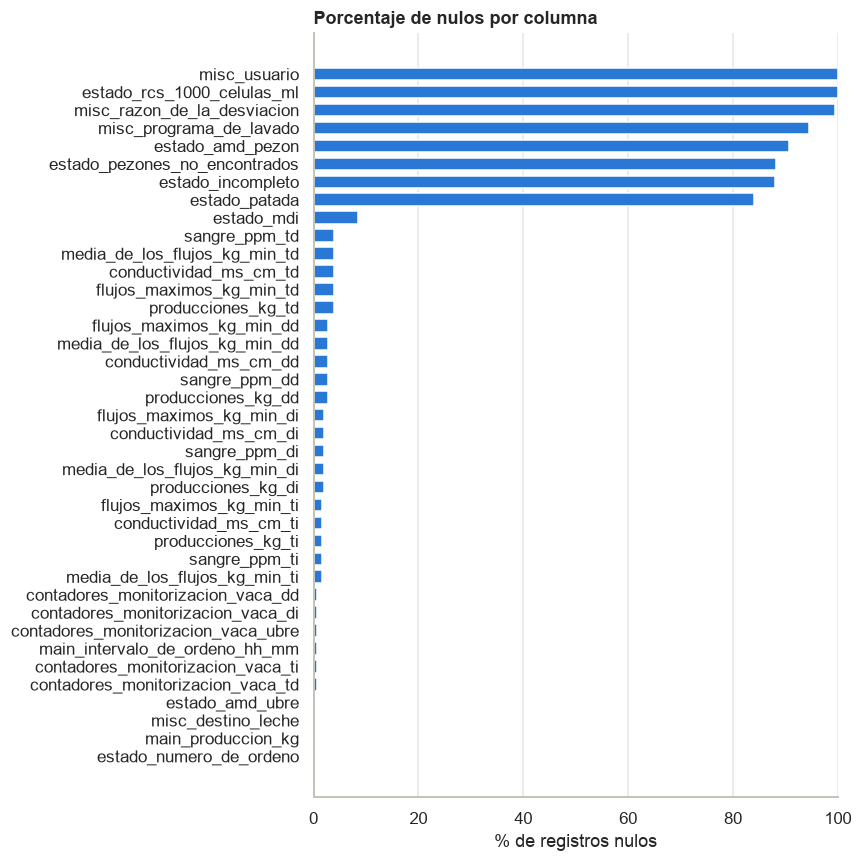

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
orden = nulos[nulos["nulos"] > 0].sort_values("porcentaje")
ax.barh(orden.index, orden["porcentaje"], color=AZUL, height=0.7)
ax.set_title("Porcentaje de nulos por columna")
ax.set_xlabel("% de registros nulos")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

El porcentaje por sí solo engaña: casi ningún nulo es un dato "perdido". Se revisa de dónde viene cada bloque.

In [11]:
df_sin_prod = df[df["main_produccion_kg"].isna()]
df_prod = df[df["main_produccion_kg"].notna()]

print(f"Registros con produccion: {df_prod.shape[0]:,} | Registros sin produccion: {df_sin_prod.shape[0]:,}")
print("Registros de echadas sin ordeñar: ", df[(df["main_accion"] == "Echada sin ordeñar")].shape[0])
print("Registros de rechazadas: ", df[(df["main_accion"] == "Rechazada")].shape[0])

Registros con produccion: 280,699 | Registros sin produccion: 216
Registros de echadas sin ordeñar:  46


Registros de rechazadas:  170


**Observaciones:** La producción total es nula solo en las 216 visitas que no fueron ordeño (170 rechazadas y 46 echadas sin ordeñar, todas del csv), que son 0.08 % de los registros; los 280,699 ordeños siempre la traen. Son nulos estructurales y no datos perdidos: no se deben imputar, y las mediciones por cuarto (flujos, sangre, conductividad) se analizan solo sobre los ordeños. Como el xlsx no trae `main_accion`, sus 278,968 registros se toman como ordeños y no se pueden contar rechazos antes de 2025.

In [12]:
# Nulos por cuarto: estan repartidos o concentrados en vacas especificas?
ordenos = df[df["main_produccion_kg"].notna()]
total = 0
for cuarto in ["di", "dd", "ti", "td"]:
    cuarto_nulo = ordenos[ordenos[f"producciones_kg_{cuarto}"] == 0]
    print(f"Cuarto {cuarto.upper()} distribucion en las máquinas: \n")
    nulos_por_maquina = cuarto_nulo.groupby("misc_eo_po").size().sort_values(ascending=False)
    print(nulos_por_maquina.to_string())
    print(f"Cuarto {cuarto.upper()} sin registro de produccion total: ", cuarto_nulo.shape[0])
    total += cuarto_nulo.shape[0]
print(f"Total de nulos en todos los cuartos: {total}")

Cuarto DI distribucion en las máquinas: 

misc_eo_po
86696b37    1954
7063e4b1    1451
b96e85be    1116
Cuarto DI sin registro de produccion total:  4521
Cuarto DD distribucion en las máquinas: 

misc_eo_po
b96e85be    1792
86696b37    1378
7063e4b1    1059
Cuarto DD sin registro de produccion total:  4229
Cuarto TI distribucion en las máquinas: 

misc_eo_po
7063e4b1    4369
86696b37    4237
b96e85be    4219
Cuarto TI sin registro de produccion total:  12825
Cuarto TD distribucion en las máquinas: 

misc_eo_po
b96e85be    4784
86696b37    4677
7063e4b1    3752
Cuarto TD sin registro de produccion total:  13213
Total de nulos en todos los cuartos: 34788


**Observaciones:** Aunque en estos ordeños se obtuvo leche de la vaca, en 28,615 de ellos (10.2 %) al menos un cuarto de la ubre quedó sin producción, y en total son 34,788 casos de cuarto sin leche. Los cuartos traseros concentran 26,038 (75 %) y fallan en cerca de 4.6 % de los ordeños cada uno, contra 1.5 % de los delanteros. La distribución es casi igual en las tres máquinas, así que no parece un problema de una máquina en particular. Un cuarto sin producción coincide con ordeño incompleto en 83 % de los casos (contra 4 % cuando todos los cuartos producen).

In [13]:
for cuarto in ["di", "dd", "ti", "td"]:
    es_cero = ordenos[ordenos[f"conductividad_ms_cm_{cuarto}"] == 0]
    sin_leche = ordenos[ordenos[f"producciones_kg_{cuarto}"] == 0]
    print(f"Cuarto {cuarto.upper()} con conductividad 0 de cada máquina: \n")
    cero_maquina = es_cero.groupby("misc_eo_po")
    sin_leche_maquina = sin_leche.groupby("misc_eo_po")
    for maquina in ordenos["misc_eo_po"].unique():
        n_cero = cero_maquina.size().get(maquina, 0)
        n_sin_leche = sin_leche_maquina.size().get(maquina, 0)
        print(f"Máquina {maquina}: conductividad 0 en {n_cero:,} ordeños; "
              f"sin leche en {n_sin_leche:,} ordeños")


Cuarto DI con conductividad 0 de cada máquina: 

Máquina 7063e4b1: conductividad 0 en 1,513 ordeños; sin leche en 1,451 ordeños
Máquina 86696b37: conductividad 0 en 1,976 ordeños; sin leche en 1,954 ordeños
Máquina b96e85be: conductividad 0 en 1,149 ordeños; sin leche en 1,116 ordeños
Máquina 55926a71: conductividad 0 en 0 ordeños; sin leche en 0 ordeños
Cuarto DD con conductividad 0 de cada máquina: 

Máquina 7063e4b1: conductividad 0 en 1,785 ordeños; sin leche en 1,059 ordeños
Máquina 86696b37: conductividad 0 en 1,382 ordeños; sin leche en 1,378 ordeños
Máquina b96e85be: conductividad 0 en 5,871 ordeños; sin leche en 1,792 ordeños
Máquina 55926a71: conductividad 0 en 0 ordeños; sin leche en 0 ordeños
Cuarto TI con conductividad 0 de cada máquina: 

Máquina 7063e4b1: conductividad 0 en 8,069 ordeños; sin leche en 4,369 ordeños
Máquina 86696b37: conductividad 0 en 9,444 ordeños; sin leche en 4,237 ordeños
Máquina b96e85be: conductividad 0 en 5,769 ordeños; sin leche en 4,219 ordeños


**Observaciones:** La conductividad de la leche no puede ser 0, así que esos valores son lecturas faltantes que `.isna()` no detecta. En DI el cero coincide con el cuarto sin leche en las tres máquinas (4,638 ceros contra 4,521 cuartos sin leche), pero en DD y TI hay más ceros que cuartos sin leche (9,038 contra 4,229 y 23,282 contra 12,825), o sea ceros con leche producida, que son fallas de lectura. El caso más grave es TD en la máquina `b96e85be`: 70,604 ceros (89 % de los de TD) contra 4,784 cuartos sin leche, lo que apunta a un sensor que no registra; en las otras dos máquinas los ceros de TD sí coinciden con los cuartos sin leche. Estos ceros deben tratarse como faltantes y reportarse al cliente.

**Tipos de nulo en el dataset**

| Tipo | Columnas | Qué significa | Tratamiento sugerido |
| :-- | :-- | :-- | :-- |
| Columna vacía (100 %) | `estado_rcs_1000_celulas_ml` | El recuento de células somáticas no se registra en ningún ordeño | Eliminar |
| Columna vacía (100 %) | `misc_usuario` | Usuario que intervino manualmente; no hay ninguno registrado en todo el periodo | Eliminar |
| Casi vacía (99.5 %) | `misc_razon_de_la_desviacion` | Solo 1,542 registros con motivo del desvío de la leche (casi todos por sangre) | Convertir a 0/1 (leche desviada) |
| Casi vacía (94.4 %) | `misc_programa_de_lavado` | Solo trae el valor «Local Aclarado» y solo en el xlsx | Confirmar su significado con el cliente |
| Nulo = "no ocurrió" (84–91 %) | `estado_patada`, `estado_incompleto`, `estado_pezones_no_encontrados`, `estado_amd_pezon` | La celda vacía significa que el evento **no** pasó | Convertir a 0/1, no imputar |
| Nulo estructural (0.08 %) | Todas las mediciones | Son las 216 visitas que no fueron ordeño | Separar por tipo de visita |
| Columnas de una sola fuente (0.7 %) | `main_intervalo_de_ordeno_hh_mm`, `contadores_monitorizacion_vaca_*`, `estado_mdi` | Solo existen en el xlsx; faltan en los 1,947 registros del csv que no estaban en el xlsx (`estado_mdi` falta además en 7.8 % del xlsx) | Calcular el intervalo con la hora de inicio |
| Cuarto no ordeñado | `*_di`, `*_dd`, `*_ti`, `*_td` | En 1 o 2 vacas por cuarto la medición falta en todos sus ordeños | Confirmar con el socio formador |
| Cero como nulo | `conductividad_ms_cm_*` | En DI, DD y TI el 0 aparece cuando el cuarto no dio leche. En TD, 28 % de los ordeños tienen 0 y la mayoría viene de la máquina `b96e85be` (72 % de sus ordeños, más de 90 % desde 2024) | Tratar como faltante y confirmar con el cliente |

Los problemas de calidad reales son los ceros de conductividad y los cuartos sin medición; el resto es información, no ausencia de ella.

## 4. Datos duplicados

In [14]:
duplicados = df.duplicated(subset=["id_vaca", "misc_eo_po", "main_hora_de_inicio"], keep=False)

print(f"Filas duplicadas por vaca, máquina y minuto de inicio:", duplicados.sum())
df[duplicados]

Filas duplicadas por vaca, máquina y minuto de inicio: 15


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,estado_numero_de_ordeno,estado_rcs_1000_celulas_ml,estado_patada,estado_incompleto,estado_pezones_no_encontrados,estado_amd_ubre,estado_amd_pezon,media_de_los_flujos_kg_min_di,media_de_los_flujos_kg_min_dd,media_de_los_flujos_kg_min_ti,media_de_los_flujos_kg_min_td,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td,conductividad_ms_cm_di,conductividad_ms_cm_dd,conductividad_ms_cm_ti,conductividad_ms_cm_td,misc_eo_po,misc_usuario,misc_destino_leche,misc_razon_de_la_desviacion,flujos_maximos_kg_min_di,flujos_maximos_kg_min_dd,flujos_maximos_kg_min_ti,flujos_maximos_kg_min_td,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,main_intervalo_de_ordeno_hh_mm,contadores_monitorizacion_vaca_ubre,contadores_monitorizacion_vaca_di,contadores_monitorizacion_vaca_dd,contadores_monitorizacion_vaca_ti,contadores_monitorizacion_vaca_td,misc_programa_de_lavado,estado_mdi,fuente,inicio,duracion_seg
272,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7063e4b1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-05-06 14:46:00,0.0
273,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7063e4b1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-05-06 14:46:00,0.0
614,7588fd14,16/03/2025 05:35 a. m.,Ordeño,08:51,13.87,1.0,NaN,NaN,NaN,NaN,0.0,NaN,0.66,0.78,0.72,0.78,0.0,0.0,0.0,0.0,4.32,4.56,4.59,0.0,b96e85be,NaN,Tanque,NaN,0.96,1.32,1.08,1.20,2.79,2.71,4.22,4.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-16 05:35:00,531.0
615,7588fd14,16/03/2025 05:35 a. m.,Echada sin ordeñar,08:50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,b96e85be,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-16 05:35:00,530.0
1040,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86696b37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-05-28 07:30:00,0.0
1041,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86696b37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-05-28 07:30:00,0.0
1485,7648b6a6,27/06/2025 01:39 p. m.,Ordeño,09:23,12.43,1.0,NaN,NaN,NaN,NaN,0.0,NaN,0.72,0.72,NaN,0.84,0.0,0.0,NaN,0.0,4.92,5.19,NaN,4.9,7063e4b1,NaN,Tanque,NaN,1.14,1.26,NaN,1.38,3.57,3.07,NaN,5.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-06-27 13:39:00,563.0
1486,7648b6a6,27/06/2025 01:39 p. m.,Echada sin ordeñar,09:23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7063e4b1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-06-27 13:39:00,563.0
1586,e202cdc8,16/03/2025 02:48 a. m.,Ordeño,05:05,11.72,1.0,NaN,NaN,NaN,NaN,0.0,NaN,1.14,1.20,1.20,1.14,0.0,0.0,0.0,0.0,4.80,4.69,4.71,0.0,b96e85be,NaN,Tanque,NaN,1.44,1.68,1.74,1.62,2.67,3.07,2.95,3.03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-16 02:48:00,305.0
1587,e202cdc8,16/03/2025 02:48 a. m.,Echada sin ordeñar,05:04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,b96e85be,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-16 02:48:00,304.0


**Observaciones:** Hay muy pocos duplicados en el dataset ya unificado: 7 grupos de registros (15 filas) repiten vaca, máquina y hora de inicio, y solo 2 son copias exactas (dos pares de rechazos de 00:00 de las vacas `3851395f` y `5e57b4f1`), que pueden ser un error de captura y se pueden eliminar sin perder información. Los otros 5 no son copias: en tres, un `Ordeño` y un `Echada sin ordeñar` duran lo mismo (con 1 s de diferencia como máximo), así que parecen la misma visita registrada dos veces, y en los otros dos (vacas `a878349c` y `e202cdc8`) hay intentos cortos seguidos, de 1 a 46 s. El duplicado importante es otro: 5,302 registros del csv de 2025 ya estaban en el xlsx con distinto formato de hora y duración, y se quitaron al cargar los datos para no contarlos dos veces.

## 5. Ciclo de lactancia

Una vaca lechera sigue una curva de lactancia: después del parto la producción **sube** durante unas semanas hasta un **pico**, luego **baja** poco a poco y, antes del siguiente parto, la vaca se **seca** (deja de ordeñarse unos 60 días). Si esa curva se ve en los datos, la etapa de lactancia de cada vaca se puede tomar en cuenta para saber cuánta leche es normal esperar de ella.

El dataset no trae fecha de parto ni días en leche, así que la etapa solo se puede inferir de la forma de la producción diaria.

In [15]:
# Produccion diaria por vaca: suma de todos los ordeños del dia
visitas = df[df["main_produccion_kg"] > 0].copy()
visitas["fecha"] = visitas["inicio"].dt.normalize()


diaria = (visitas.groupby(["id_vaca", "fecha"])
          .agg(kg=("main_produccion_kg", "sum"), ordeños=("main_produccion_kg", "size"))
          .reset_index().sort_values(["id_vaca", "fecha"]))
diaria["dias_sin_ordeño"] = diaria.groupby("id_vaca")["fecha"].diff().dt.days
calendario = pd.date_range(diaria["fecha"].min(), diaria["fecha"].max())

# La produccion del dia depende de cuantas veces vino la vaca
# vacas = cuantas vacas distintas tuvieron al menos un dia con ese numero de ordeños
# kg_mediana = mediana de kg de esos dias
resumen_dia = (diaria.groupby("ordeños")
               .agg(vacas=("id_vaca", "nunique"), kg_mediana=("kg", "median"))
               .round(1))
resumen_dia.index.name = "ordeños_en_el_dia"
print("Vacas ordeñadas según el número de ordeños en el día:")
resumen_dia


Vacas ordeñadas según el número de ordeños en el día:


,vacas,kg_mediana
ordeños_en_el_dia,,
1,207,17.6
2,206,31.1
3,202,42.0
4,173,53.3
5,88,61.3
6,11,60.3


In [16]:
def serie_diaria(vaca):
    """Produccion diaria de una vaca sobre el calendario completo (dias sin ordeño = NaN) y su promedio movil de 7 dias."""
    kg = diaria[diaria["id_vaca"] == vaca].set_index("fecha")["kg"].reindex(calendario)
    return kg, kg.rolling(7, min_periods=3, center=True).mean()


# Resumen por vaca: dias con ordeño y ausencias de mas de 40 dias (posible periodo de secado)
resumen_vacas = diaria.groupby("id_vaca").agg(
    dias=("fecha", "size"), primer_dia=("fecha", "min"), ultimo_dia=("fecha", "max"),
    ausencias=("dias_sin_ordeño", lambda s: (s > 40).sum()))
print(f"Vacas: {len(resumen_vacas)} | con al menos 30 días de ordeño: {(resumen_vacas['dias'] >= 30).sum()} | "
      f"con alguna ausencia de más de 40 días: {(resumen_vacas['ausencias'] > 0).sum()}")
resumen_vacas["dias"].describe().round(0).to_frame("días con ordeño por vaca").T

Vacas: 207 | con al menos 30 días de ordeño: 200 | con alguna ausencia de más de 40 días: 133


,count,mean,std,min,25%,50%,75%,max
días con ordeño por vaca,207.0,561.0,351.0,2.0,268.0,520.0,933.0,1164.0


### 5.1 Producción diaria de cada vaca

Cada punto gris es la producción total de un día y la línea azul es el promedio móvil de 7 días. Se muestran las 30 vacas con más días de ordeño, con historias de unos tres años que incluyen varias lactancias.

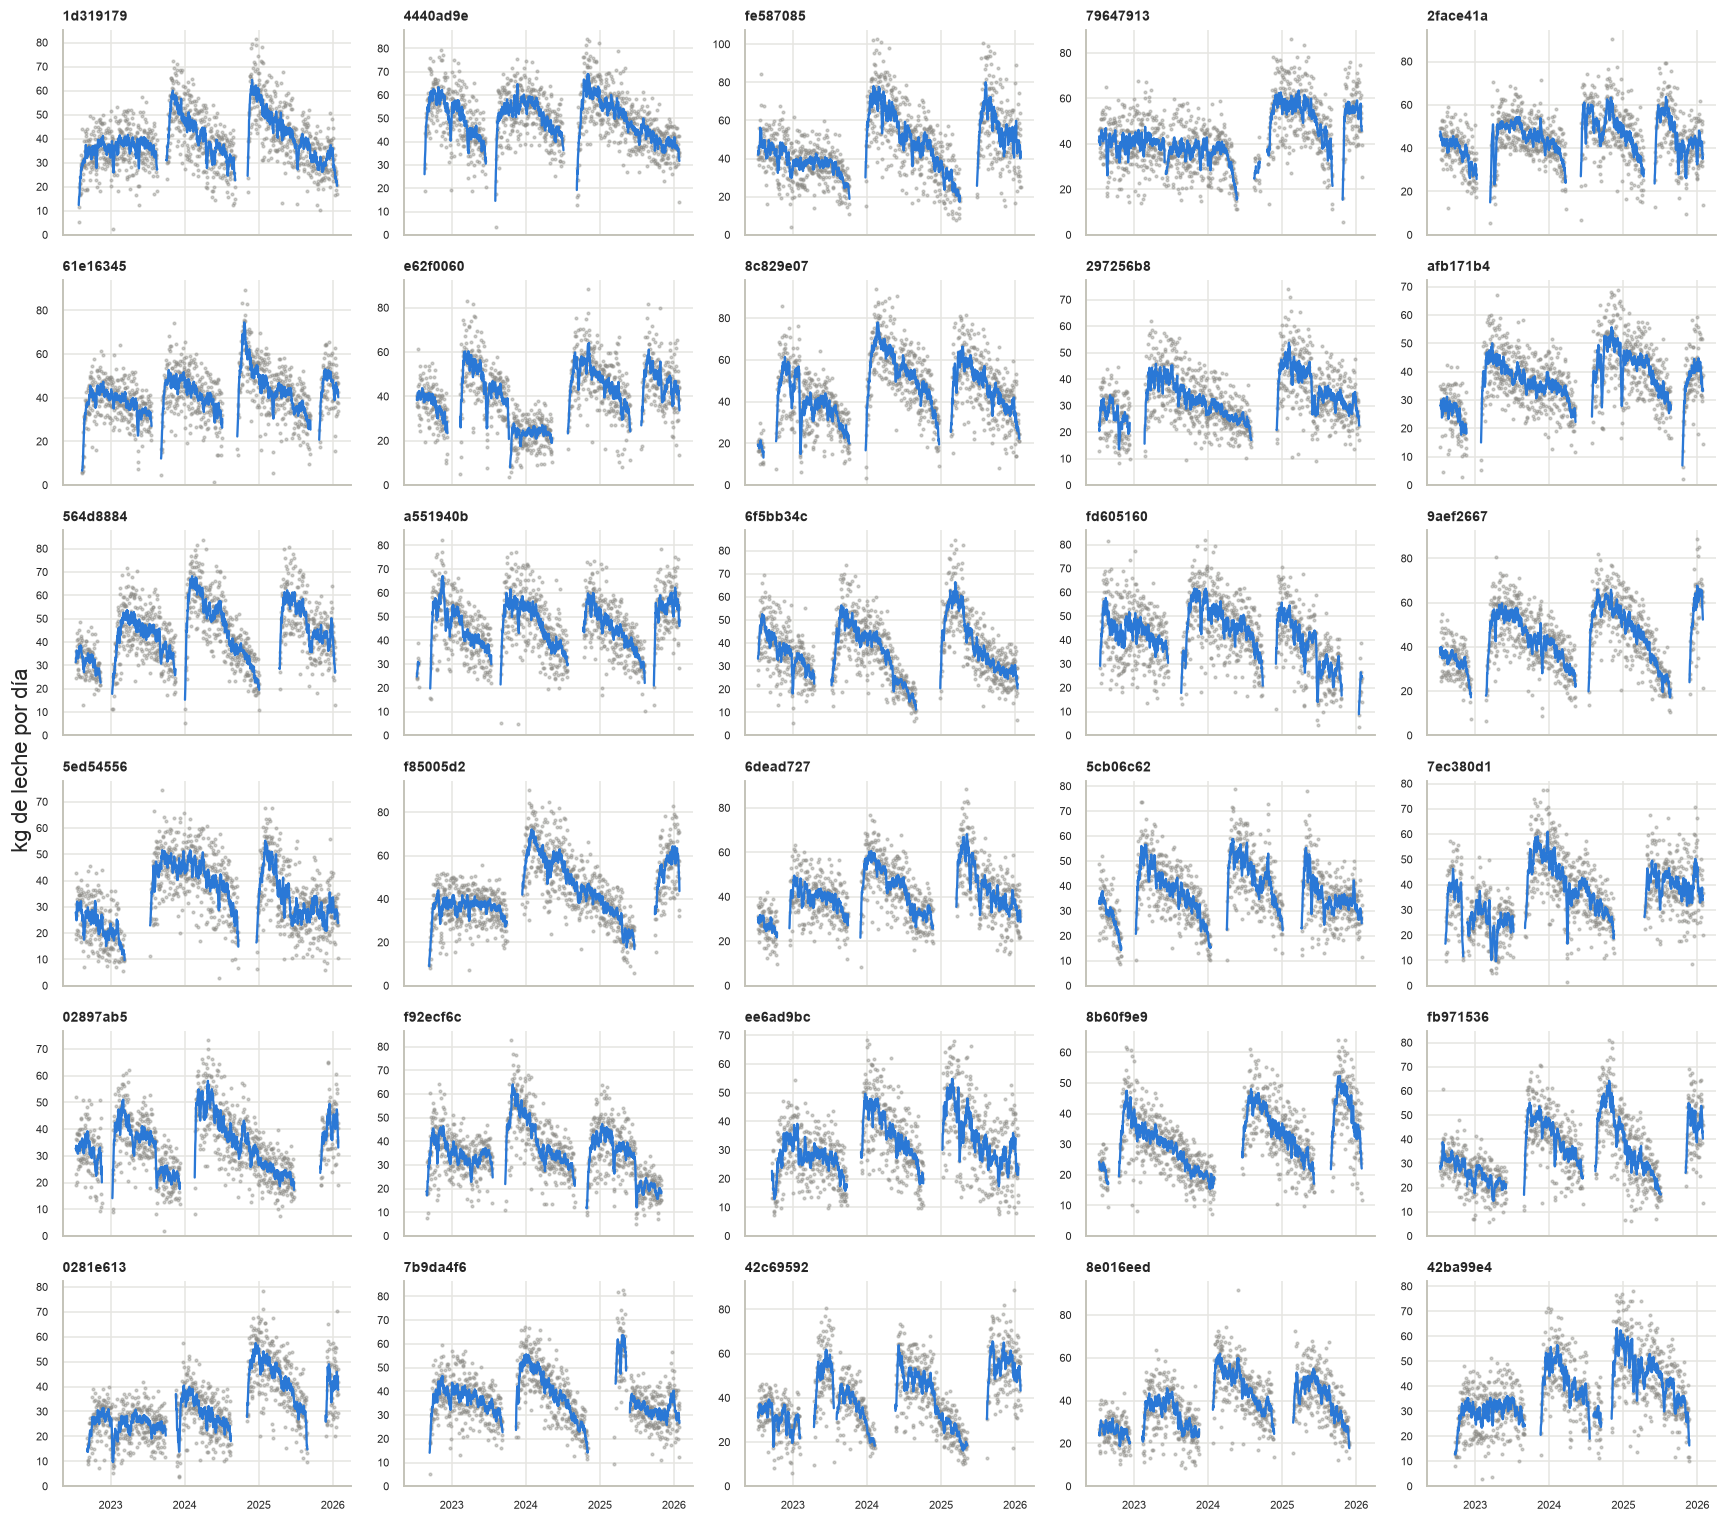

In [17]:
# Las 30 vacas con mas dias de ordeño (las historias mas largas)
largas = resumen_vacas.sort_values("dias", ascending=False).head(30).index

fig, axes = plt.subplots(6, 5, figsize=(16, 14), sharex=True)
for ax, vaca in zip(axes.flat, largas):
    kg, suave = serie_diaria(vaca)
    ax.scatter(kg.index, kg.values, s=3, color=GRIS, alpha=0.4)
    ax.plot(suave.index, suave.values, color=AZUL, linewidth=1.5)
    ax.set_title(vaca, fontsize=9)
    ax.set_ylim(0, None)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.supylabel("kg de leche por día")
plt.tight_layout()
plt.show()

### 5.2 Vacas que se ausentan y regresan

Las zonas naranjas son los días sin ningún ordeño. Se muestran 8 ejemplos tomados al azar de las ausencias de más de 40 días en las que la vaca tiene al menos 30 días con ordeño antes y después; la tabla resume todas esas ausencias.

Ausencias de más de 40 días con historia a los dos lados: 237 de 129 vacas


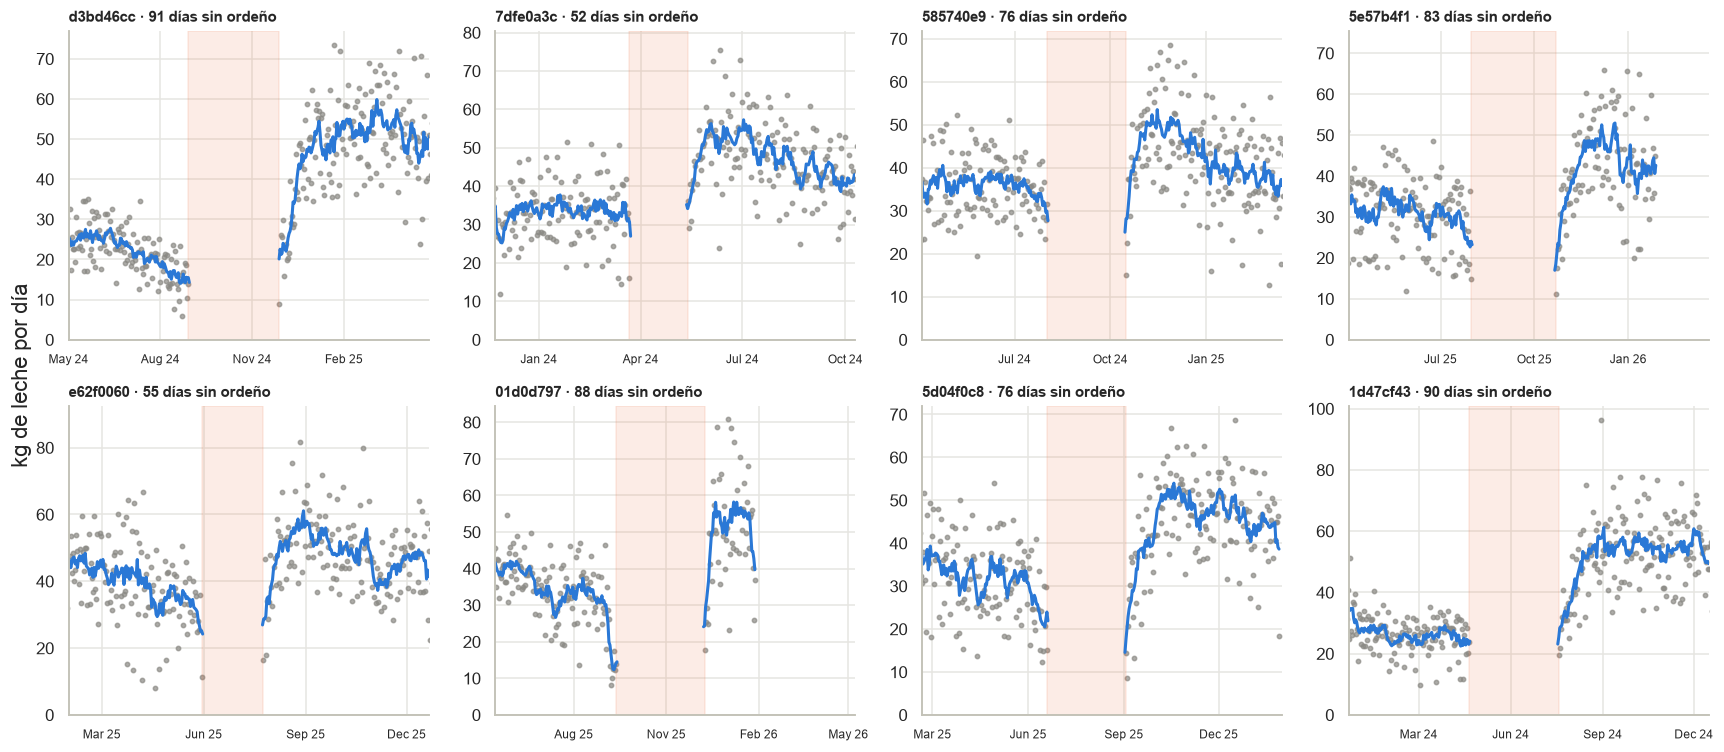

,dias_ausente,kg_antes,kg_primeros_3_dias,kg_pico_7d,dias_hasta_el_pico
25%,64.0,21.0,19.0,51.0,34.0
50%,81.0,25.0,24.0,55.0,45.0
75%,100.0,29.0,29.0,61.0,60.0


In [18]:
# Ausencias de mas de 40 dias de vacas con historia antes y despues (al menos 30 dias con ordeño en cada lado)
ausentes = diaria[diaria["dias_sin_ordeño"] > 40][["id_vaca", "fecha", "dias_sin_ordeño"]]
dias_por_vaca = diaria.groupby("id_vaca")["fecha"]
ausentes = ausentes[[
    ((diaria["id_vaca"] == v) & (diaria["fecha"] < f - pd.Timedelta(days=int(d)))).sum() >= 30
    and ((diaria["id_vaca"] == v) & (diaria["fecha"] >= f)).sum() >= 30
    for v, f, d in ausentes.itertuples(index=False)]]
print(f"Ausencias de más de 40 días con historia a los dos lados: {len(ausentes)} de {len(ausentes.id_vaca.unique())} vacas")

ejemplos = ausentes.sample(8, random_state=1)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (vaca, regreso, dias) in zip(axes.flat, ejemplos.itertuples(index=False)):
    kg, suave = serie_diaria(vaca)
    ax.scatter(kg.index, kg.values, s=8, color=GRIS, alpha=0.7)
    ax.plot(suave.index, suave.values, color=AZUL, linewidth=2)
    ax.axvspan(regreso - pd.Timedelta(days=int(dias)), regreso, color=NARANJA, alpha=0.12)
    ax.set_xlim(regreso - pd.Timedelta(days=int(dias) + 120), regreso + pd.Timedelta(days=150))
    ax.set_title(f"{vaca} · {int(dias)} días sin ordeño", fontsize=10)
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    ax.tick_params(axis="x", labelsize=8)
fig.supylabel("kg de leche por día")
plt.tight_layout()
plt.show()

# Que tanto sube la produccion despues de regresar (todas las ausencias)
filas = []
for vaca, regreso, dias in ausentes.itertuples(index=False):
    despues = diaria[(diaria["id_vaca"] == vaca) & (diaria["fecha"] >= regreso)]
    suave = serie_diaria(vaca)[1][regreso:regreso + pd.Timedelta(days=90)]   # el pico se busca en los primeros 90 dias
    filas.append({
        "dias_ausente": int(dias),
        "kg_antes": diaria[(diaria["id_vaca"] == vaca) & (diaria["fecha"] < regreso - pd.Timedelta(days=int(dias)))]["kg"].tail(14).mean(),
        "kg_primeros_3_dias": despues["kg"].head(3).mean(),
        "kg_pico_7d": suave.max(),
        "dias_hasta_el_pico": (suave.idxmax() - regreso).days,
    })
retornos = pd.DataFrame(filas)
retornos.describe().loc[["25%", "50%", "75%"]].round(0)

**Observaciones:** La curva de lactancia se repite en cada vaca: la producción sube tras el parto hasta un pico, baja de forma gradual y la vaca deja de ordeñarse antes del siguiente ciclo. De las 237 ausencias de más de 40 días (de 129 vacas), la mediana dura 81 días, lo que coincide con un periodo de secado; al volver producen unos 24 kg al día, como antes de irse (25 kg), y llegan a un pico de unos 55 kg en una mediana de 45 días. Los puntos diarios son dispersos porque dependen de cuántas veces vino la vaca (17.6 kg con un ordeño, 31.1 con dos y 42.0 con tres), así que conviene leer el promedio de 7 días. Sin fecha de parto, la etapa de lactancia solo se infiere de estas curvas.

## 6. Patrones y distribuciones

Primero se ven las distribuciones de las variables principales, después cómo se usan las máquinas y al final se compara la producción entre máquinas, cuartos y vacas.

In [19]:
# Variables auxiliares para las graficas de esta seccion (no se guardan en disco)
sesiones = df.drop_duplicates().copy()
sesiones["duracion_min"] = sesiones["duracion_seg"] / 60
sesiones["fin"] = sesiones["inicio"] + pd.to_timedelta(sesiones["duracion_seg"], unit="s")
sesiones["fecha"] = sesiones["inicio"].dt.normalize()
sesiones["hora"] = sesiones["inicio"].dt.hour

# Una "maquina" del archivo tiene solo 2 registros: se deja fuera
maquinas = sorted(sesiones["misc_eo_po"].value_counts().loc[lambda s: s > 100].index)
sesiones = sesiones[sesiones["misc_eo_po"].isin(maquinas)]

# Horas desde el ordeño anterior de la misma vaca (solo entre ordeños)
sesiones = sesiones.sort_values(["id_vaca", "inicio"])
es_ordeno = sesiones["main_accion"] == "Ordeño"
sesiones.loc[es_ordeno, "horas_desde_anterior"] = (
    sesiones[es_ordeno].groupby("id_vaca")["inicio"].diff().dt.total_seconds() / 3600
)
ordenos_ses = sesiones[es_ordeno].copy()

# Un color fijo por maquina en todas las graficas
color_maquina = dict(zip(maquinas, [AZUL, NARANJA, AQUA]))
print(f"Ordeños: {len(ordenos_ses):,} | Máquinas: {maquinas}")

Ordeños: 280,697 | Máquinas: ['7063e4b1', '86696b37', 'b96e85be']


### 6.1 Distribuciones

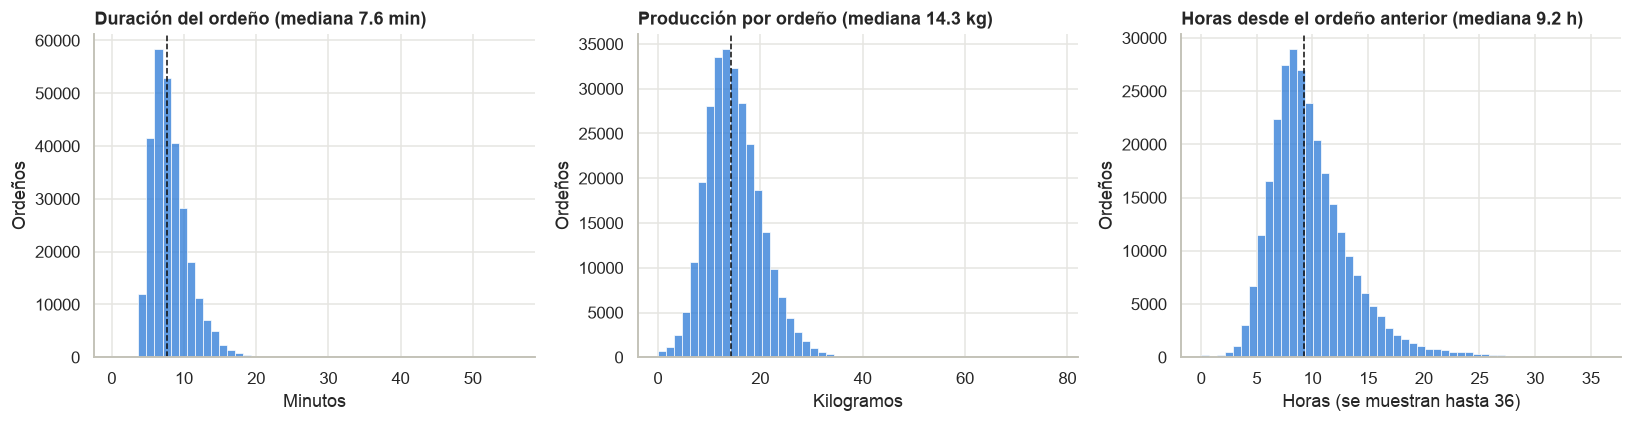

Intervalos de más de 36 h entre ordeños: 633


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(ordenos_ses["duracion_min"], bins=50, color=AZUL, ax=axes[0])
axes[0].axvline(ordenos_ses["duracion_min"].median(), color="#0b0b0b", linestyle="--", linewidth=1)
axes[0].set_title(f"Duración del ordeño (mediana {ordenos_ses['duracion_min'].median():.1f} min)")
axes[0].set_xlabel("Minutos")

sns.histplot(ordenos_ses["main_produccion_kg"], bins=50, color=AZUL, ax=axes[1])
axes[1].axvline(ordenos_ses["main_produccion_kg"].median(), color="#0b0b0b", linestyle="--", linewidth=1)
axes[1].set_title(f"Producción por ordeño (mediana {ordenos_ses['main_produccion_kg'].median():.1f} kg)")
axes[1].set_xlabel("Kilogramos")

intervalo = ordenos_ses["horas_desde_anterior"].dropna()
sns.histplot(intervalo[intervalo <= 36], bins=50, color=AZUL, ax=axes[2])
axes[2].axvline(intervalo.median(), color="#0b0b0b", linestyle="--", linewidth=1)
axes[2].set_title(f"Horas desde el ordeño anterior (mediana {intervalo.median():.1f} h)")
axes[2].set_xlabel("Horas (se muestran hasta 36)")

for ax in axes:
    ax.set_ylabel("Ordeños")
plt.tight_layout()
plt.show()

print(f"Intervalos de más de 36 h entre ordeños: {(intervalo > 36).sum()}")

**Observaciones:** Las tres variables son asimétricas a la derecha. La mitad central de los ordeños dura entre 6.3 y 9.4 min (mediana de 7.6), produce entre 11.1 y 18.1 kg (mediana de 14.3) y ocurre entre 7.4 y 11.7 h después del anterior (mediana de 9.2). Las colas largas son poco frecuentes pero existen: ordeños de hasta 56 min, 633 intervalos de más de 36 h entre ordeños de una misma vaca y 166 ordeños con 0 kg. Conviene revisar esos extremos antes de modelar, porque un ordeño muy largo ocupa la máquina mucho más de lo normal.

### 6.2 Uso de las máquinas

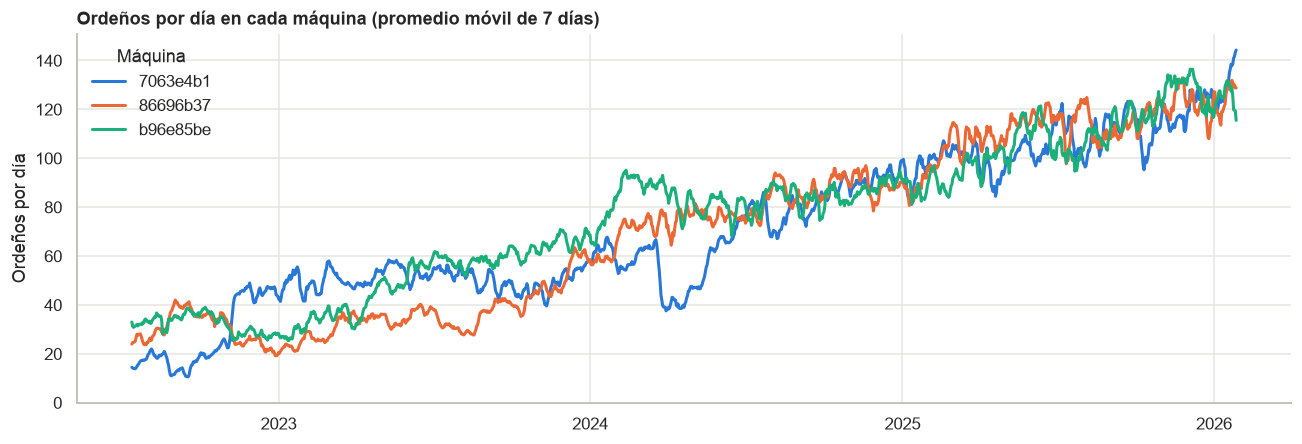

Vacas distintas por semana en cada máquina (una semana de cada 13; la primera y la ultima semanas estan incompletas):


misc_eo_po,7063e4b1,86696b37,b96e85be
2022-07-11,5,13,16
2022-10-10,10,15,18
2023-01-09,25,10,12
2023-04-10,19,16,20
2023-07-10,25,13,25
2023-10-09,20,16,25
2024-01-08,37,23,32
2024-04-08,17,37,47
2024-07-08,37,32,37
2024-10-07,35,34,33


In [21]:
# Ordeños por dia en cada maquina (se quita el ultimo dia, que esta incompleto)
dias_completos = pd.date_range(sesiones["fecha"].min(), sesiones["fecha"].max())[:-1]
por_dia = (ordenos_ses.groupby(["fecha", "misc_eo_po"]).size().unstack(fill_value=0)
           .reindex(index=dias_completos, columns=maquinas, fill_value=0))

fig, ax = plt.subplots(figsize=(12, 4.2))
for maquina in maquinas:
    ax.plot(por_dia.index, por_dia[maquina].rolling(7, min_periods=3, center=True).mean(),
            color=color_maquina[maquina], linewidth=2, label=maquina)
ax.set_title("Ordeños por día en cada máquina (promedio móvil de 7 días)")
ax.set_ylabel("Ordeños por día")
ax.set_ylim(0, None)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(title="Máquina", frameon=False)
plt.tight_layout()
plt.show()

print("Vacas distintas por semana en cada máquina (una semana de cada 13; la primera y la ultima semanas estan incompletas):")
por_semana = (ordenos_ses.groupby([ordenos_ses["inicio"].dt.to_period("W").dt.start_time, "misc_eo_po"])["id_vaca"]
              .nunique().unstack(fill_value=0))
por_semana.index = por_semana.index.date
por_semana.iloc[::13]

**Observaciones:** Las tres máquinas atienden una carga parecida y creciente: pasaron de 14 a 31 ordeños diarios en julio de 2022 a entre 120 y 141 en enero de 2026 (promedio móvil de 7 días), y las vacas distintas por semana en cada máquina subieron de 5–16 a 51–68. La máquina `7063e4b1` cae a unos 38 ordeños diarios a finales de marzo de 2024, contra unos 63 a mediados de febrero, una baja que conviene revisar con el cliente (mantenimiento o falla). Como el hato creció de 34 a 182 vacas con las mismas tres máquinas (sección 7), la carga de cada máquina es lo que determina la cola.

## 7. Clima, correlación y cola

Con el dataset unificado se agregan el clima por hora de NASA POWER (hora local), la matriz de correlación y el análisis de la cola entre una vaca y la siguiente.

In [22]:
# Ordeños del historial completo (df ya unifica el csv y el xlsx)
ordenos = df[df["main_accion"] == "Ordeño"].sort_values(["id_vaca", "inicio"]).copy()
ordenos["fin"] = ordenos["inicio"] + pd.to_timedelta(ordenos["duracion_seg"], unit="s")
ordenos["duracion_min"] = ordenos["duracion_seg"] / 60
ordenos["horas_desde_anterior"] = ordenos.groupby("id_vaca")["inicio"].diff().dt.total_seconds() / 3600

maquinas = ordenos["misc_eo_po"].value_counts().loc[lambda s: s > 100].index.tolist()   # una "maquina" tiene solo 2 registros
ordenos = ordenos[ordenos["misc_eo_po"].isin(maquinas)].reset_index(drop=True)
print(f"Ordeños: {len(ordenos):,} | vacas: {ordenos['id_vaca'].nunique()} | máquinas: {len(maquinas)} | "
      f"{ordenos['inicio'].min():%d/%m/%Y} a {ordenos['inicio'].max():%d/%m/%Y}")

Ordeños: 280,697 | vacas: 207 | máquinas: 3 | 13/07/2022 a 28/01/2026


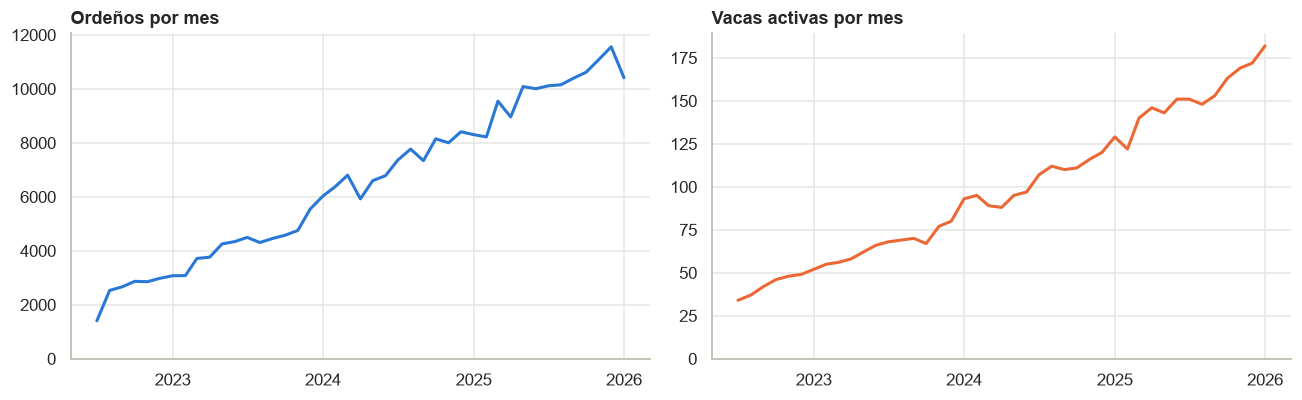

,ordeños,vacas
inicio,,
2022-07-01,1406,34
2025-12-01,11559,172
2026-01-01,10414,182


In [23]:
# Crecimiento del hato: ordeños y vacas activas por mes
mensual = ordenos.groupby(ordenos["inicio"].dt.to_period("M").dt.to_timestamp()).agg(ordeños=("id_vaca", "size"), vacas=("id_vaca", "nunique"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(mensual.index, mensual["ordeños"], color=AZUL, linewidth=2); axes[0].set_title("Ordeños por mes")
axes[1].plot(mensual.index, mensual["vacas"], color=NARANJA, linewidth=2); axes[1].set_title("Vacas activas por mes")
for ax in axes:
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

# Julio de 2022 y enero de 2026 estan incompletos (empiezan el dia 13 y terminan el 28)
mensual.iloc[[0, -2, -1]]

Clima: 31,104 horas | 13/07/2022 a 28/01/2026 | nulos: 0


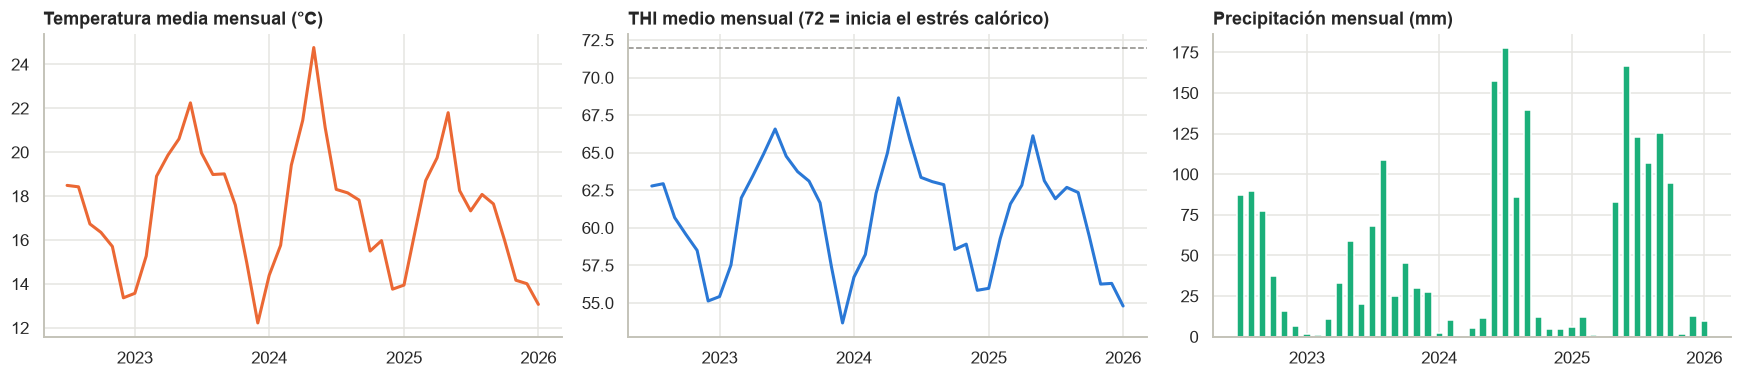

,mean,std,min,max
t2m,17.39,6.32,0.60,35.91
rh2m,61.38,28.46,2.94,100.00
t2mdew,7.61,5.90,-16.82,17.68
t2mwet,12.50,3.89,-3.25,20.80
qv2m,8.83,3.07,0.97,16.08
ps,79.01,0.20,78.04,79.78
ws2m,2.38,1.37,0.02,10.41
ws10m,3.46,1.73,0.04,14.26
wd10m,134.99,92.85,0.00,359.80
prectotcorr,0.07,0.23,0.00,10.27


In [24]:
# EDA del clima (NASA POWER, hora local)
clima = pd.read_csv(raiz / "Data" / "clima" / "clima_nasa_power_por_hora.csv", parse_dates=["hora"])
# Indice de temperatura-humedad (THI): medida usual de estres calorico en vacas lecheras
clima["thi"] = (1.8 * clima["t2m"] + 32) - (0.55 - 0.0055 * clima["rh2m"]) * (1.8 * clima["t2m"] - 26)
print(f"Clima: {len(clima):,} horas | {clima['hora'].min():%d/%m/%Y} a {clima['hora'].max():%d/%m/%Y} | nulos: {clima.isna().sum().sum()}")

mes = clima.set_index("hora").resample("MS")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
axes[0].plot(mes["t2m"].mean(), color=NARANJA, linewidth=2); axes[0].set_title("Temperatura media mensual (°C)")
axes[1].plot(mes["thi"].mean(), color=AZUL, linewidth=2); axes[1].axhline(72, color=GRIS, linestyle="--", linewidth=1)
axes[1].set_title("THI medio mensual (72 = inicia el estrés calórico)")
axes[2].bar(mes["prectotcorr"].sum().index, mes["prectotcorr"].sum().values, width=20, color=AQUA); axes[2].set_title("Precipitación mensual (mm)")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

clima.drop(columns="hora").describe().T[["mean", "std", "min", "max"]].round(2)

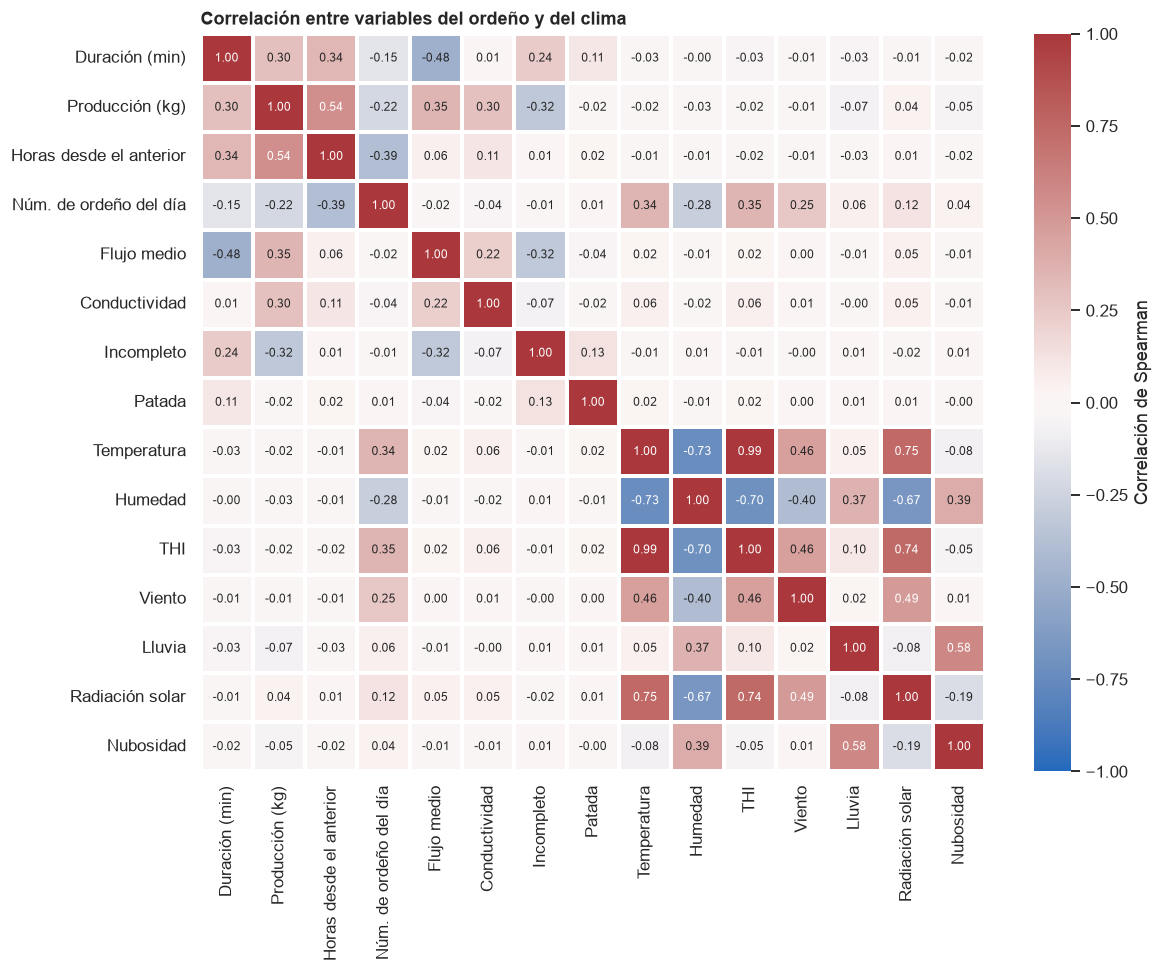

In [25]:
# Matriz de correlacion: ordeño + clima de la hora de inicio (Spearman, por la asimetria de las variables)
datos = ordenos.merge(clima, left_on=ordenos["inicio"].dt.floor("h"), right_on="hora", how="left", suffixes=("", "_clima")).drop(columns=["key_0"], errors="ignore")
cuartos = ["di", "dd", "ti", "td"]
conductividad = datos[[f"conductividad_ms_cm_{c}" for c in cuartos]].replace(0, np.nan)   # un 0 de conductividad es lectura faltante

variables = pd.DataFrame({
    "Duración (min)": datos["duracion_min"],
    "Producción (kg)": datos["main_produccion_kg"],
    "Horas desde el anterior": datos["horas_desde_anterior"],
    "Núm. de ordeño del día": datos["estado_numero_de_ordeno"],
    "Flujo medio": datos[[f"media_de_los_flujos_kg_min_{c}" for c in cuartos]].mean(axis=1),
    "Conductividad": conductividad.mean(axis=1),
    "Incompleto": datos["estado_incompleto"].notna().astype(int),
    "Patada": datos["estado_patada"].notna().astype(int),
    "Temperatura": datos["t2m"],
    "Humedad": datos["rh2m"],
    "THI": datos["thi"],
    "Viento": datos["ws2m"],
    "Lluvia": datos["prectotcorr"],
    "Radiación solar": datos["allsky_sfc_sw_dwn"],
    "Nubosidad": datos["cloud_amt"],
})

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(variables.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            linewidths=1.5, linecolor="white", annot_kws={"size": 8}, cbar_kws={"label": "Correlación de Spearman"}, ax=ax)
ax.set_title("Correlación entre variables del ordeño y del clima")
plt.tight_layout(); plt.show()

**Observaciones:** El clima casi no se relaciona con el ordeño: sus correlaciones con la producción, la duración, el flujo, la conductividad y los eventos de patada o incompleto son de 0.07 o menos en valor absoluto, así que el clima de la hora no explica por sí solo la producción ni los problemas. Lo que sí pesa es el propio proceso: la producción sube con las horas desde el ordeño anterior (0.54) y con la duración (0.30), y baja en los ordeños incompletos (−0.32), mientras que el flujo medio cae al alargarse el ordeño (−0.48). El número de ordeño del día correlaciona con la temperatura (0.34) probablemente por la hora del día y no por un efecto del calor, y como temperatura y THI son casi la misma variable (0.99), basta usar una.

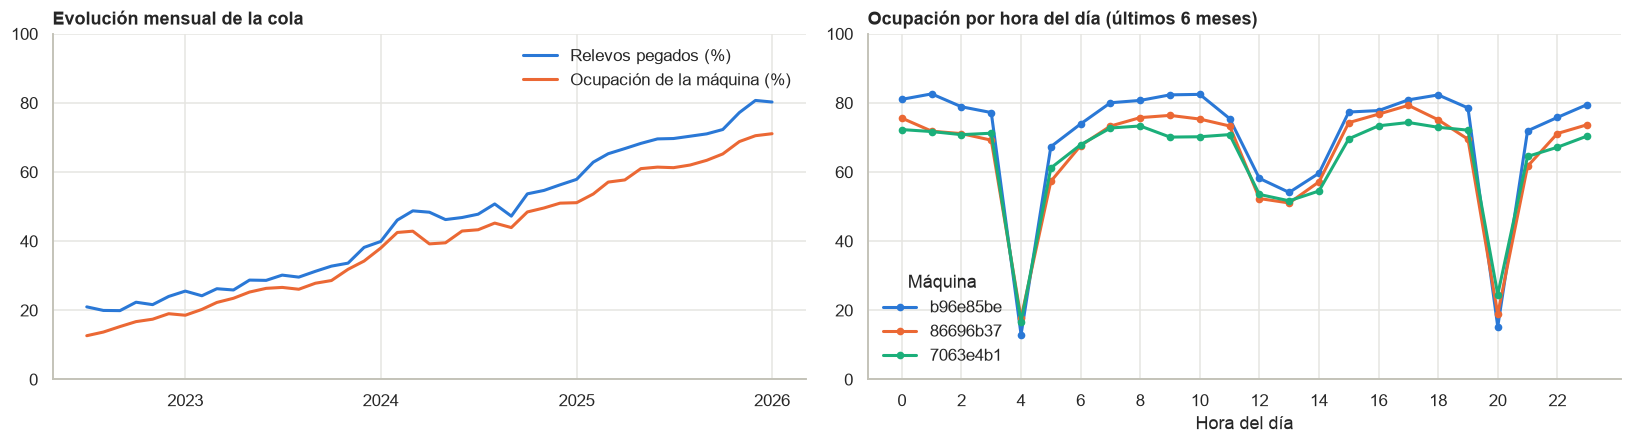

,ordeños_por_día,ocupación_%,relevos_pegados_%,hueco_mediano_min,espera_estimada_min
máquina,,,,,
b96e85be,125.8,73.4,84.3,0.5,12.9
86696b37,121.6,68.8,77.7,0.6,9.9
7063e4b1,121.5,66.6,75.2,0.5,8.8


In [26]:
# Cola: tiempo libre de la maquina = inicio de la vaca siguiente - (inicio + duracion) de la anterior
UMBRAL_MIN = 2   # un relevo a 2 min o menos del fin de la vaca anterior se considera "pegado"

cola = ordenos.sort_values(["misc_eo_po", "inicio", "fin"]).copy()
por_maquina = cola.groupby("misc_eo_po")
cola["hueco_min"] = ((cola["inicio"] - por_maquina["fin"].shift()).dt.total_seconds() / 60).clip(lower=0)
cola["vaca_anterior"] = por_maquina["id_vaca"].shift()
relevos = cola[cola["vaca_anterior"].notna() & (cola["vaca_anterior"] != cola["id_vaca"])].copy()
relevos["pegado"] = relevos["hueco_min"] <= UMBRAL_MIN

# Por mes: relevos pegados y ocupacion de las maquinas (promedio de las tres)
mes_r = relevos["inicio"].dt.to_period("M").dt.to_timestamp()
mes_o = ordenos["inicio"].dt.to_period("M").dt.to_timestamp()
dias_mes = ordenos.groupby(mes_o)["inicio"].apply(lambda s: s.dt.normalize().nunique())
ocupacion = ordenos.groupby(mes_o)["duracion_seg"].sum() / dias_mes / 86400 / len(maquinas) * 100
pegados = relevos.groupby(mes_r)["pegado"].mean() * 100

# Por hora del dia, ultimos 6 meses: ocupacion de cada maquina
reciente = ordenos[ordenos["inicio"] >= ordenos["inicio"].max() - pd.DateOffset(months=6)]
dias_rec = reciente["inicio"].dt.normalize().nunique()
por_hora = (reciente.groupby([reciente["inicio"].dt.hour, "misc_eo_po"])["duracion_seg"].sum().unstack() / dias_rec / 3600 * 100)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].plot(pegados.index, pegados.values, color=AZUL, linewidth=2, label="Relevos pegados (%)")
axes[0].plot(ocupacion.index, ocupacion.values, color=NARANJA, linewidth=2, label="Ocupación de la máquina (%)")
axes[0].set_ylim(0, 100); axes[0].legend(frameon=False); axes[0].set_title("Evolución mensual de la cola")
axes[0].xaxis.set_major_locator(mdates.YearLocator()); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for maquina, color in zip(maquinas, [AZUL, NARANJA, AQUA]):
    axes[1].plot(por_hora.index, por_hora[maquina], color=color, linewidth=2, marker="o", markersize=4, label=maquina)
axes[1].set_xticks(range(0, 24, 2)); axes[1].set_ylim(0, 100); axes[1].legend(title="Máquina", frameon=False)
axes[1].set_title("Ocupación por hora del día (últimos 6 meses)"); axes[1].set_xlabel("Hora del día")
plt.tight_layout(); plt.show()

# Resumen de los ultimos 3 meses por maquina; espera estimada con la formula de Pollaczek-Khinchine (llegadas al azar)
ult = ordenos["inicio"] >= ordenos["inicio"].max() - pd.DateOffset(months=3)
dias_ult = ordenos.loc[ult, "inicio"].dt.normalize().nunique()
resumen = []
for maquina in maquinas:
    o = ordenos[ult & (ordenos["misc_eo_po"] == maquina)]
    r = relevos[(relevos["inicio"] >= o["inicio"].min()) & (relevos["misc_eo_po"] == maquina)]
    rho = o["duracion_seg"].sum() / dias_ult / 86400
    media, cv = o["duracion_min"].mean(), o["duracion_min"].std() / o["duracion_min"].mean()
    resumen.append({"máquina": maquina, "ordeños_por_día": len(o) / dias_ult, "ocupación_%": rho * 100,
                    "relevos_pegados_%": r["pegado"].mean() * 100, "hueco_mediano_min": r["hueco_min"].median(),
                    "espera_estimada_min": rho * media * (1 + cv ** 2) / (2 * (1 - rho))})
pd.DataFrame(resumen).set_index("máquina").round(1)

**Observaciones y conclusiones:** El historial creció de 34 a 182 vacas activas por mes (de 1.4 mil a 11.6 mil ordeños mensuales) con las mismas tres máquinas, y el clima casi no se relaciona con el ordeño (|r| ≤ 0.07 con producción, duración e incompletos), mientras que las horas desde el ordeño anterior sí (r = 0.54 con la producción). Sí hay problema de cola: entre 2022 y 2026 los relevos pegados pasaron de 21 % a 80 % y la ocupación de 13 % a 71 %; hoy cada máquina hace unos 120 ordeños al día, con 67–73 % de ocupación y una espera estimada de 9 a 13 min por vaca, y solo las paradas de las 4:00 y las 20:00 dan holgura. La espera es una estimación con llegadas al azar; para confirmarla falta la hora de llegada de cada vaca.

## 8. Sangre en la leche y mastitis

Se revisa qué tan seguido aparece sangre en la leche (`sangre_ppm_*`) y con qué frecuencia la conductividad es alta, que es el indicador que se usa para sospechar de mastitis. El dataset no trae una etiqueta de mastitis y el recuento de células somáticas está vacío, así que la conductividad alta es solo un indicador: no confirma la enfermedad, y el proyecto no hace diagnóstico veterinario.

In [27]:
# Sangre y conductividad por ordeño
cuartos = ["di", "dd", "ti", "td"]
UMBRAL_CONDUCTIVIDAD = 6.5   # mS/cm: valor de referencia de conductividad alta (por confirmar con el socio formador)

sangre = ordenos[[f"sangre_ppm_{c}" for c in cuartos]]
conductividad = ordenos[[f"conductividad_ms_cm_{c}" for c in cuartos]].replace(0, np.nan)   # un 0 es lectura faltante

ordenos["sangre_max"] = sangre.max(axis=1)
ordenos["con_sangre"] = ordenos["sangre_max"] > 0
ordenos["conductividad_alta"] = (conductividad >= UMBRAL_CONDUCTIVIDAD).any(axis=1)

filas = {}
for c in cuartos:
    s = ordenos[f"sangre_ppm_{c}"]
    filas[c.upper()] = {
        "ordeños con sangre (%)": (s > 0).mean() * 100,
        "mediana de ppm si hay sangre": s[s > 0].median(),
        "sangre de 1,000 ppm o más (%)": (s >= 1000).mean() * 100,
        f"conductividad ≥ {UMBRAL_CONDUCTIVIDAD} (%)": (conductividad[f"conductividad_ms_cm_{c}"] >= UMBRAL_CONDUCTIVIDAD).mean() * 100,
    }
filas["Cualquier cuarto"] = {
    "ordeños con sangre (%)": ordenos["con_sangre"].mean() * 100,
    "mediana de ppm si hay sangre": ordenos.loc[ordenos["con_sangre"], "sangre_max"].median(),
    "sangre de 1,000 ppm o más (%)": (ordenos["sangre_max"] >= 1000).mean() * 100,
    f"conductividad ≥ {UMBRAL_CONDUCTIVIDAD} (%)": ordenos["conductividad_alta"].mean() * 100,
}
pd.DataFrame(filas).T.round(1)

,ordeños con sangre (%),mediana de ppm si hay sangre,"sangre de 1,000 ppm o más (%)",conductividad ≥ 6.5 (%)
DI,2.6,553.0,0.8,0.7
DD,2.3,427.0,0.3,0.6
TI,1.4,436.0,0.2,0.6
TD,1.1,484.0,0.2,1.1
Cualquier cuarto,5.5,459.0,1.1,2.7


In [28]:
# A donde va la leche segun la sangre y la conductividad
grupos = {
    "Sin sangre": ordenos["sangre_max"] == 0,
    "Sangre de 1 a 500 ppm": ordenos["sangre_max"].between(1, 500),
    "Sangre de 501 a 1,000 ppm": ordenos["sangre_max"].between(501, 1000),
    "Sangre de más de 1,000 ppm": ordenos["sangre_max"] > 1000,
    f"Conductividad ≥ {UMBRAL_CONDUCTIVIDAD}": ordenos["conductividad_alta"],
}
destino = {}
for nombre, mascara in grupos.items():
    d = ordenos.loc[mascara, "misc_destino_leche"]
    destino[nombre] = {"ordeños": int(mascara.sum()), "Tanque (%)": (d == "Tanque").mean() * 100,
                       "Drenaje (%)": (d == "Drenaje").mean() * 100, "Divert 3 (%)": (d == "Divert 3").mean() * 100}
pd.DataFrame(destino).T.round(1).astype({"ordeños": int})

,ordeños,Tanque (%),Drenaje (%),Divert 3 (%)
Sin sangre,265381,96.0,3.6,0.5
Sangre de 1 a 500 ppm,8744,88.3,5.5,6.2
"Sangre de 501 a 1,000 ppm",3436,58.9,7.6,33.4
"Sangre de más de 1,000 ppm",3136,13.3,7.7,78.9
Conductividad ≥ 6.5,7611,84.9,12.7,2.4


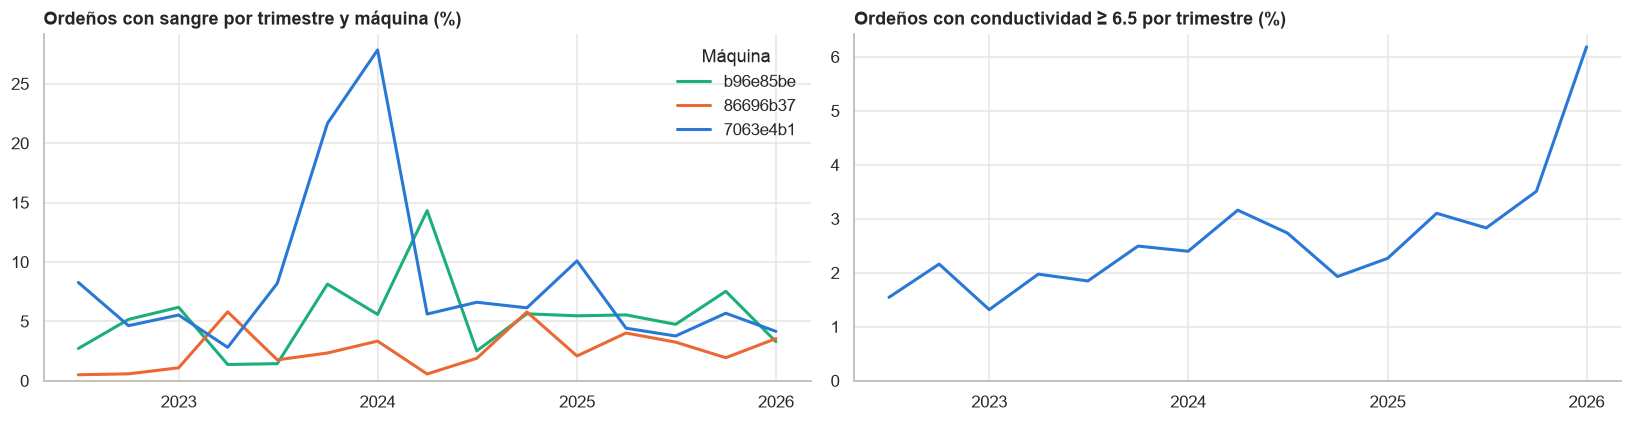

Los 3 trimestres con más ordeños con sangre (máquina, % de sus ordeños):
inicio      misc_eo_po
2024-01-01  7063e4b1      27.8
2023-10-01  7063e4b1      21.7
2024-04-01  b96e85be      14.3

Ordeños con conductividad alta por año (%):
inicio
2022    1.9
2023    2.0
2024    2.5
2025    3.0
2026    6.2

Vacas con al menos 200 ordeños en dos máquinas o más: 132
% de ordeños con sangre por máquina en esas mismas vacas:
misc_eo_po
7063e4b1    8.4
86696b37    2.9
b96e85be    6.4

Vacas con sangre alguna vez: 204 de 207 | con sangre en más del 5 % de sus ordeños: 88
Vacas con conductividad alta en más del 10 % de sus ordeños: 12 | las 10 vacas con más casos concentran 38% de los ordeños con conductividad alta


In [29]:
# Evolucion en el tiempo
trimestre = ordenos["inicio"].dt.to_period("Q").dt.to_timestamp()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

por_trimestre = ordenos.groupby([trimestre, "misc_eo_po"])["con_sangre"].mean().unstack() * 100
for maquina in maquinas:
    axes[0].plot(por_trimestre.index, por_trimestre[maquina], color=color_maquina[maquina], linewidth=2, label=maquina)
axes[0].set_title("Ordeños con sangre por trimestre y máquina (%)")
axes[0].legend(title="Máquina", frameon=False)

alta_trimestre = ordenos.groupby(trimestre)["conductividad_alta"].mean() * 100
axes[1].plot(alta_trimestre.index, alta_trimestre.values, color=AZUL, linewidth=2)
axes[1].set_title(f"Ordeños con conductividad ≥ {UMBRAL_CONDUCTIVIDAD} por trimestre (%)")

for ax in axes:
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

print("Los 3 trimestres con más ordeños con sangre (máquina, % de sus ordeños):")
print(por_trimestre.stack().nlargest(3).round(1).to_string())
print("\nOrdeños con conductividad alta por año (%):")
print((ordenos.groupby(ordenos["inicio"].dt.year)["conductividad_alta"].mean() * 100).round(1).to_string())
print()

# La diferencia entre maquinas, es de las vacas? Se compara a las mismas vacas en distintas maquinas
base = ordenos.groupby(["id_vaca", "misc_eo_po"])["con_sangre"].agg(["mean", "size"]).reset_index()
base = base[base["size"] >= 200].pivot(index="id_vaca", columns="misc_eo_po", values="mean").dropna(thresh=2)
print(f"Vacas con al menos 200 ordeños en dos máquinas o más: {len(base)}")
print("% de ordeños con sangre por máquina en esas mismas vacas:")
print((base.mean() * 100).round(1).to_string())

# Estan concentradas en pocas vacas?
por_vaca = ordenos.groupby("id_vaca").agg(sangre=("con_sangre", "mean"), alta=("conductividad_alta", "mean"), n_alta=("conductividad_alta", "sum"))
print(f"\nVacas con sangre alguna vez: {(por_vaca['sangre'] > 0).sum()} de {len(por_vaca)} | con sangre en más del 5 % de sus ordeños: {(por_vaca['sangre'] > 0.05).sum()}")
print(f"Vacas con conductividad alta en más del 10 % de sus ordeños: {(por_vaca['alta'] > 0.1).sum()} | "
      f"las 10 vacas con más casos concentran {por_vaca['n_alta'].nlargest(10).sum() / por_vaca['n_alta'].sum():.0%} de los ordeños con conductividad alta")

**Observaciones:** Aparece sangre en 5.5 % de los ordeños y en 204 de las 207 vacas, más en los cuartos delanteros (2.6 % en DI) que en los traseros (1.1 % en TD); solo 1.1 % de los ordeños pasan de 1,000 ppm. La leche se desvía según la cantidad: con más de 1,000 ppm el 78.9 % va a `Divert 3` (0.5 % sin sangre), mientras que con conductividad ≥ 6.5 (2.7 % de los ordeños) lo que sube es el drenaje (12.7 % contra 3.6 %). La sangre tiene picos por máquina, de hasta 27.8 % de los ordeños en `7063e4b1` en el primer trimestre de 2024, y las mismas vacas dan 8.4 %, 2.9 % y 6.4 % según la máquina, así que conviene revisar esos sensores con el cliente. La conductividad alta subió de 1.9 % en 2022 a 3.0 % en 2025 y se concentra en pocas vacas (12 con más del 10 % de sus ordeños).

## 9. Eventos que no son ordeños normales

Se revisa qué tan frecuentes son los eventos que interrumpen o complican el ordeño: patada, ordeño incompleto, pezón no encontrado y alerta AMD, y cuáles ocurren juntos. Los rechazos y las visitas de «echada sin ordeñar» solo se registran en el csv de 2025, así que se miden aparte.

In [30]:
# Frecuencia de cada evento por ordeño
eventos = {"Patada": "estado_patada", "Incompleto": "estado_incompleto",
           "Pezón no encontrado": "estado_pezones_no_encontrados", "AMD pezón": "estado_amd_pezon"}
for nombre, columna in eventos.items():
    ordenos[nombre] = ordenos[columna].notna()
ordenos["AMD ubre"] = ordenos["estado_amd_ubre"] == 1


def porcentaje_cuarto(columna, cuarto):
    """% de los ordeños en los que el evento afecta a ese cuarto (la columna guarda la lista de cuartos o 'Todos')."""
    texto = ordenos[columna].fillna("")
    return (texto.str.contains(cuarto.upper()) | (texto == "Todos")).mean() * 100


filas = {}
for nombre, columna in eventos.items():
    por_vaca = ordenos.groupby("id_vaca")[nombre].mean()
    filas[nombre] = {
        "ordeños": int(ordenos[nombre].sum()),
        "% de los ordeños": ordenos[nombre].mean() * 100,
        **{f"{c.upper()} (%)": porcentaje_cuarto(columna, c) for c in cuartos},
        "duración con evento (min)": ordenos.loc[ordenos[nombre], "duracion_min"].median(),
        "duración sin evento (min)": ordenos.loc[~ordenos[nombre], "duracion_min"].median(),
        "vacas con el evento en más del 20 %": int((por_vaca > 0.2).sum()),
    }
filas["AMD ubre"] = {"ordeños": int(ordenos["AMD ubre"].sum()), "% de los ordeños": ordenos["AMD ubre"].mean() * 100}
alguno = ordenos[list(eventos)].any(axis=1)
filas["Al menos uno de los cuatro"] = {"ordeños": int(alguno.sum()), "% de los ordeños": alguno.mean() * 100}
tabla_eventos = pd.DataFrame(filas).T.round(1)
tabla_eventos.astype({"ordeños": "Int64", "vacas con el evento en más del 20 %": "Int64"})

,ordeños,% de los ordeños,DI (%),DD (%),TI (%),TD (%),duración con evento (min),duración sin evento (min),vacas con el evento en más del 20 %
Patada,45119,16.1,5.8,3.1,3.7,7.2,8.3,7.5,58
Incompleto,33517,11.9,2.5,2.3,5.4,5.6,9.5,7.4,40
Pezón no encontrado,33022,11.8,2.0,1.9,5.0,5.4,9.9,7.4,44
AMD pezón,26241,9.3,2.9,2.5,2.4,3.1,8.4,7.5,25
AMD ubre,34277,12.2,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
Al menos uno de los cuatro,91402,32.6,NaN,NaN,NaN,NaN,NaN,NaN,<NA>


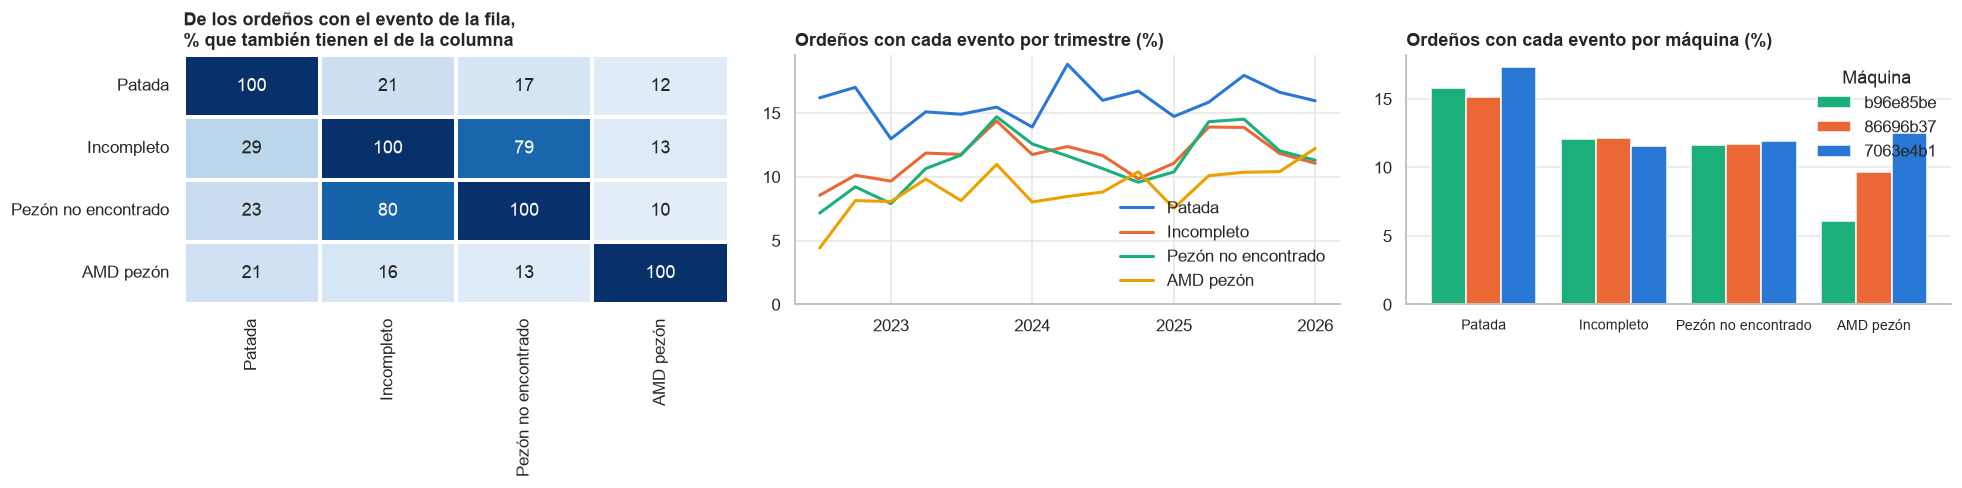

        Patada  Incompleto  Pezón no encontrado  AMD pezón
inicio                                                    
2022      16.7         9.4                  8.3        6.5
2023      14.7        12.1                 11.6        9.4
2024      16.4        11.3                 11.0        9.0
2025      16.4        12.7                 12.9        9.7
2026      16.0        11.1                 11.3       12.2



,Patada,Incompleto,Pezón no encontrado,AMD pezón
misc_eo_po,,,,
b96e85be,15.8,12.1,11.6,6.1
86696b37,15.1,12.1,11.7,9.7
7063e4b1,17.3,11.6,12.0,12.5


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
nombres = list(eventos)
color_evento = dict(zip(nombres, [AZUL, NARANJA, AQUA, "#eda100"]))

# Que eventos ocurren juntos
coincidencia = pd.DataFrame({b: {a: ordenos.loc[ordenos[a], b].mean() * 100 for a in nombres} for b in nombres})
sns.heatmap(coincidencia, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, linewidths=1.5, linecolor="white", cbar=False, ax=axes[0])
axes[0].set_title("De los ordeños con el evento de la fila,\n% que también tienen el de la columna")

# Evolucion por trimestre
por_trimestre = ordenos.groupby(trimestre)[nombres].mean() * 100
for nombre in nombres:
    axes[1].plot(por_trimestre.index, por_trimestre[nombre], color=color_evento[nombre], linewidth=2, label=nombre)
axes[1].set_title("Ordeños con cada evento por trimestre (%)")
axes[1].set_ylim(0, None); axes[1].legend(frameon=False)
axes[1].xaxis.set_major_locator(mdates.YearLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Por maquina
por_maquina_evento = ordenos.groupby("misc_eo_po")[nombres].mean().reindex(maquinas) * 100
x = np.arange(len(nombres))
for k, maquina in enumerate(maquinas):
    axes[2].bar(x + (k - 1) * 0.27, por_maquina_evento.loc[maquina], width=0.27, color=color_maquina[maquina], label=maquina)
axes[2].set_xticks(x, nombres, fontsize=9)
axes[2].set_title("Ordeños con cada evento por máquina (%)")
axes[2].legend(title="Máquina", frameon=False); axes[2].grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

# Porcentaje de ordeños con cada evento por año y por maquina
print((ordenos.groupby(ordenos["inicio"].dt.year)[nombres].mean() * 100).round(1))
print()
(por_maquina_evento).round(1)

In [32]:
# Rechazos y echadas sin ordeñar: solo los registra el csv (marzo a julio de 2025, 34 vacas)
visitas_csv = bruto[bruto["fuente"] == "csv"]
resumen_visitas = visitas_csv["main_accion"].value_counts().to_frame("visitas")
resumen_visitas["%"] = (resumen_visitas["visitas"] / resumen_visitas["visitas"].sum() * 100).round(1)
resumen_visitas

,visitas,%
main_accion,,
Ordeño,7016,96.8
Rechazada,172,2.4
Echada sin ordeñar,61,0.8


**Observaciones:** Uno de cada tres ordeños (32.6 %) tiene al menos un evento: patada en 16.1 %, incompleto en 11.9 %, pezón no encontrado en 11.8 % y alerta AMD de pezón en 9.3 %. El incompleto y el pezón no encontrado son casi el mismo evento (79 y 80 % de coincidencia), afectan más a los cuartos traseros (5.0 a 5.6 % contra 1.9 a 2.5 % de los delanteros) y alargan el ordeño unos 2 min (9.5 y 9.9 contra 7.4 min). Las frecuencias son parecidas en las tres máquinas, salvo AMD pezón (de 6.1 % a 12.5 %), y subieron desde 2022 (el incompleto, de 9.4 % a 12.7 % en 2025); 40 vacas tienen incompletos en más del 20 % de sus ordeños, así que no es un problema de unas pocas. Los rechazos y las echadas sin ordeñar solo se registran en 2025: 2.4 % y 0.8 % de las visitas.